# Prediksi Status Penanganan Pengiriman

**Kompetisi Datavidia 11.0.** Notebook ini membangun model yang membaca jejak operasional sebuah pengiriman (pemindaian, kaki rute, tagihan, pelanggan, kurir, hub) lalu menandai satu dari tujuh `status_penanganan`. Metrik penilaian adalah **Macro F1**, sehingga kelas jarang seperti `klaim_hilang` sama pentingnya dengan kelas `normal`.

## Ringkasan hasil

| Hal | Hasil |
|---|---|
| Skor validasi (OOF 5-fold, Macro F1) | **0,6187** (rentang per fold 0,6178 sampai 0,6198) |
| Log loss OOF | 0,7860 |
| Model | Stacking: target encoding, regresi logistik, lalu ensemble LightGBM 40%, XGBoost 40%, CatBoost 20% |
| Data | 1.243.617 baris train dari 9 tabel relasional, prediksi untuk 362.245 baris test |
| Fitur | 264 kandidat (225 fitur dasar, 32 target encoding, 7 logit regresi logistik), disaring menjadi 70 fitur akhir |

Skor di atas dihitung dengan cara yang tidak melihat jawaban: setiap prediksi berasal dari model yang tidak melatih baris tersebut, dan pengali keputusan tiap kelas dipelajari dari 4 fold lalu diuji pada fold kelima.

**F1 per kelas pada OOF:**

| Kelas | Precision | Recall | F1 |
|---|---:|---:|---:|
| `normal` | 0,806 | 0,837 | **0,821** |
| `konfirmasi_alamat` | 0,731 | 0,700 | **0,715** |
| `tertunda_operasional` | 0,776 | 0,749 | **0,762** |
| `gagal_antar_awal` | 0,487 | 0,496 | **0,492** |
| `retur_pengirim` | 0,540 | 0,522 | **0,531** |
| `rusak_perjalanan` | 0,491 | 0,498 | **0,494** |
| `klaim_hilang` | 0,518 | 0,514 | **0,516** |

## Cara menjalankan

Notebook ini **langsung melakukan inferensi tanpa melatih ulang**. Simpan `Datasets/` dan `models/` dalam satu folder. Notebook dapat dijalankan dari folder tersebut atau dari subfolder seperti `Code/`:

```
task 1/
├── notebook_status_penanganan.ipynb
├── requirements.txt
├── submission.csv                ← hasil notebook ini
├── Datasets/                     ← data kompetisi (train/, test/, sample_submission.csv)
└── models/                       ← berkas model yang dimuat saat inferensi
```

1. Pasang Python 3.13, lalu dependensinya: `pip install -r requirements.txt`
2. Jalankan seluruh sel dari atas ke bawah. Di laptop dengan CPU 12 thread dan RAM 16 GB, seluruh notebook selesai dalam sekitar 8 menit, dan 3,5 menit di antaranya adalah inferensi.
3. Hasil tersimpan sebagai `submission.csv`.

Pelatihan ulang bersifat opsional: set variabel lingkungan `RUN_TRAINING=1` sebelum menjalankan notebook (sekitar 1 jam 45 menit dengan CPU 12 thread).

## 1. Setup dan konfigurasi

Sel pertama mencari folder proyek, yaitu direktori kerja atau induknya yang berisi `Datasets/`. Sel berikutnya mengumpulkan seluruh keputusan yang lahir dari analisis (daftar kolom noise, fitur terpilih, hyperparameter) agar mudah diperiksa.

In [1]:
import os
from pathlib import Path

if "DATAVIDIA_BASE" not in os.environ:
    here = Path.cwd().resolve()
    project = next((p for p in (here, *here.parents) if (p / "Datasets").is_dir()), None)
    if project is None:
        raise FileNotFoundError("Folder Datasets/ tidak ditemukan. Jalankan notebook dari folder proyek atau set DATAVIDIA_BASE.")
    os.environ["DATAVIDIA_BASE"] = str(project)

In [2]:
import gc, json, os, time, warnings
from pathlib import Path

import numpy as np
import polars as pl
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, precision_recall_fscore_support
from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings("ignore")

# False = hanya inferensi memakai berkas model. True = latih ulang seluruh ensemble (sekitar 2 jam, CPU 12 thread).
RUN_TRAINING = os.environ.get("RUN_TRAINING", "0") == "1"
SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"   # uji cepat pipeline pada sampel kecil

BASE_DIR = Path(os.environ.get("DATAVIDIA_BASE", ".")).resolve()
DATA_DIR = BASE_DIR / "Datasets"
MODEL_DIR = Path(os.environ.get("DATAVIDIA_MODELS", BASE_DIR / "models"))
CACHE_DIR = Path(os.environ.get("DATAVIDIA_CACHE", BASE_DIR / ".training_cache"))
SUBMISSION_PATH = Path(os.environ.get("DATAVIDIA_SUBMISSION", BASE_DIR / "submission.csv"))

SEED = 42
N_THREADS = int(os.environ.get("N_THREADS", min(12, os.cpu_count() or 4)))
N_FOLDS = 2 if SMOKE_TEST else 5
TE_INNER_FOLDS = 3 if SMOKE_TEST else 10

TARGET = "status_penanganan"
CLASSES = ["normal", "konfirmasi_alamat", "tertunda_operasional", "gagal_antar_awal",
           "retur_pengirim", "rusak_perjalanan", "klaim_hilang"]
K = len(CLASSES)

EVENTS = ["pickup", "sortasi", "transit", "keluar_hub", "upaya_antar", "selesai"]
DEVICES = ["scanner", "pda", "manual", "gerbang_otomatis"]
MODAS = ["darat", "kereta", "laut", "udara"]
INV_TYPES = ["pengiriman", "langganan", "klaim"]
PEAK_MONTHS = [3, 10, 11, 12]
ID_COLS = ["shipment_id", "customer_id", "courier_id", "hub_id", "package_id", "promo_id"]
# Terbukti tanpa sinyal pada EDA (selisih antarkelas < 0,02 SD dan uji chi-square tidak signifikan).
NOISE_COLS = ["skor_prioritas_kirim", "indeks_rute_sekunder", "faktor_muatan_internal",
              "varian_cuaca_rute", "indeks_waktu_proses", "skor_kualitas_cek", "kota_asal", "kota_tujuan"]
CAT_COLS = ["channel", "pickup_type", "goods_category", "dest_region", "kota_asal", "kota_tujuan",
            "region", "segment", "preferred_payment", "loyalty_tier", "kota_tipe", "metode_notifikasi",
            "hub_region", "hub_type", "vehicle_type", "contract_type", "shift_code", "speed_class",
            "handling_class", "tipe_promo", "nama_promo", "rt_moda_first", "rt_moda_last", "inv_pm_first"]

# Hasil seleksi fitur (permutation importance melawan 10 kolom acak).
STACK_BASE = ["cr_sc_q_mean", "address_quality", "cu_sc_n_upaya_antar", "cu_inv_dtp_mean", "addr_x_complaint", "cu_n",
              "declared_value", "distance_km", "credit_score", "cr_sc_lgap_mean", "attempts_vs_customer", "cu_sc_q_mean",
              "speed_class", "cu_inv_has_klaim", "cu_jumlah_catatan", "complaint_index", "cr_rt_lratio_mean", "inv_dtp_max",
              "peak_x_density", "rt_n", "is_night", "sc_q_mean", "rt_longest_share", "rt_moda_first", "value_x_lowauto",
              "rt_km_udara", "cr_sc_man_rate", "preferred_payment", "rt_dur_sum", "inv_dtp_min", "inv_dtp_mean",
              "rt_lratio_min", "rt_moda_last", "man_vs_courier", "addr_x_attempts", "cu_is_cod", "is_peak_month",
              "inv_dtp15_n", "rt_lratio_mean", "sc_q_min", "rt_exp_dur", "hm_lratio", "addr_x_notes", "klaim_to_value",
              "rt_cost_sum", "sc_n_upaya_antar", "inv_dtp_klaim"]
STACK_TE = ["te_hb_klaim_", "te_cu_konfir", "te_cr_normal", "te_cu_retur_", "te_cr_gagal_", "te_cu_n", "te_cu_tertun",
            "te_cu_gagal_", "te_hb_normal", "te_cr_tertun", "te_cu_normal", "te_cu_rusak_", "te_cr_rusak_", "te_cu_klaim_",
            "te_hb_gagal_", "te_hb_konfir"]
STACK_CATS = ["preferred_payment", "speed_class", "rt_moda_first", "rt_moda_last"]
GLM_NAMES = [f"glm_{c[:6]}" for c in CLASSES]

# Entitas untuk target encoding: (kolom, prefix, kekuatan smoothing).
TE_ENTITIES = [("customer_id", "cu", 3.0), ("courier_id", "cr", 10.0), ("hub_id", "hb", 30.0), ("hub_month", "hm", 15.0)]
TE_NAMES = [n for _, p, _ in TE_ENTITIES for n in [f"te_{p}_{c[:6]}" for c in CLASSES] + [f"te_{p}_n"]]

GLM_C, GLM_ITERS = 0.3, 120
# Hasil tuning Optuna 28 trial.
LGB_PARAMS = dict(objective="multiclass", num_class=K, metric="multi_logloss", learning_rate=0.05, num_leaves=15,
                  min_data_in_leaf=2422, feature_fraction=0.8664528546494316, bagging_fraction=0.9321473921442153, bagging_freq=1,
                  lambda_l1=0.34713944210573805, lambda_l2=0.09501102203820647, min_gain_to_split=0.0013308217166414773,
                  path_smooth=5.073645642053565, max_bin=255, cat_smooth=30, min_data_per_group=200, max_cat_threshold=16,
                  seed=SEED, verbose=-1, num_threads=N_THREADS)
XGB_PARAMS = dict(objective="multi:softprob", num_class=K, tree_method="hist", eta=0.07, max_depth=6, min_child_weight=60,
                  subsample=0.8, colsample_bytree=0.6, reg_lambda=5, max_bin=255, eval_metric="mlogloss", seed=SEED, nthread=N_THREADS)
CAT_PARAMS = dict(loss_function="MultiClass", iterations=600, learning_rate=0.1, depth=7, l2_leaf_reg=6, bootstrap_type="Bernoulli",
                  subsample=0.8, rsm=0.7, border_count=128, thread_count=N_THREADS, od_type="Iter", od_wait=30, verbose=False,
                  random_seed=SEED, allow_writing_files=False)
LGB_ROUNDS, XGB_ROUNDS, CAT_MAX_ROWS = 1500, 800, 600_000
if SMOKE_TEST:
    LGB_ROUNDS, XGB_ROUNDS, CAT_MAX_ROWS = 30, 20, 40_000
    CAT_PARAMS = {**CAT_PARAMS, "iterations": 20}
    LGB_PARAMS = {**LGB_PARAMS, "min_data_in_leaf": 100}
print(f"RUN_TRAINING={RUN_TRAINING} | SMOKE_TEST={SMOKE_TEST} | threads={N_THREADS} | data={DATA_DIR}")

RUN_TRAINING=False | SMOKE_TEST=False | threads=12 | data=D:\Kuliyah\Datavidia\task 1\Datasets


In [3]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, MaxNLocator
from IPython.display import display, Markdown
from scipy.stats import chi2_contingency

INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 110,
                     "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
                     "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
                     "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
                     "xtick.color": MUTED, "ytick.color": INK2, "xtick.major.size": 0, "ytick.major.size": 0,
                     "grid.color": GRID, "grid.linewidth": 0.8, "legend.frameon": False, "legend.labelcolor": INK2})
pl.Config.set_tbl_rows(40); pl.Config.set_tbl_cols(20); pl.Config.set_fmt_str_lengths(60); pl.Config.set_tbl_hide_dataframe_shape(True)

def idn(x, d=1):
    """Format angka gaya Indonesia: 1.234,5"""
    return f"{x:,.{d}f}".replace(",", "#").replace(".", ",").replace("#", ".")
pct_axis = FuncFormatter(lambda v, _: f"{v * 100:.0f}%")

def scan(split, name):
    return pl.scan_csv(DATA_DIR / split / f"{name}.csv", infer_schema_length=200_000)

def heatmap(ax, M, xlabels, ylabels, fmt):
    ax.imshow(M, cmap=SEQ, aspect="auto", vmin=np.nanmin(M), vmax=np.nanmax(M))
    ax.set_xticks(range(len(xlabels)), xlabels, rotation=30, ha="right"); ax.set_yticks(range(len(ylabels)), ylabels)
    ax.set_xticks(np.arange(-.5, len(xlabels)), minor=True); ax.set_yticks(np.arange(-.5, len(ylabels)), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2); ax.tick_params(which="both", length=0)
    for s in ax.spines.values(): s.set_visible(False)
    mid = np.nanmin(M) + 0.5 * (np.nanmax(M) - np.nanmin(M))
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, fmt(M[i, j]), ha="center", va="center", fontsize=9, color="#ffffff" if M[i, j] > mid else INK)

## 2. Memahami data

### 2.1 Audit struktur dan integritas relasi

Sebelum memodelkan, setiap tabel diperiksa: jumlah baris, keunikan kunci, nilai kosong, dan apakah semua ID anak punya induk.

In [4]:
FACTS = [("shipments", "shipment_id"), ("scan_events", "event_id"), ("route_segments", "segment_id"), ("invoices", "invoice_id")]
DIMS = [("customers", "customer_id"), ("couriers", "courier_id"), ("hubs", "hub_id"), ("service_packages", "package_id"), ("promotions", "promo_id")]
rows, missing = [], []
for split, name, pk in [(s, n, k) for s in ("train", "test") for n, k in FACTS] + [("train", n, k) for n, k in DIMS]:
    lf = scan(split, name)
    cols = lf.collect_schema().names()
    r = lf.select([pl.len().alias("__n"), pl.col(pk).n_unique().alias("__u")] + [pl.col(c).null_count().alias(c) for c in cols]).collect(engine="streaming").row(0, named=True)
    rows.append({"tabel": f"{split}/{name}" if name in dict(FACTS) else name, "baris": r["__n"], "kolom": len(cols), "duplikat_kunci": r["__n"] - r["__u"]})
    missing += [{"tabel": f"{split}/{name}" if name in dict(FACTS) else name, "kolom": c, "kosong": r[c], "persen": round(r[c] / r["__n"] * 100, 2)} for c in cols if r[c] > 0]
display(pl.DataFrame(rows))
print("Kolom dengan nilai kosong:")
display(pl.DataFrame(missing))

checks = []
for split in ("train", "test"):
    ship = scan(split, "shipments")
    for col, dim in [("customer_id", "customers"), ("courier_id", "couriers"), ("hub_id", "hubs"), ("package_id", "service_packages"), ("promo_id", "promotions")]:
        n = ship.select(col).join(scan("train", dim).select(col), on=col, how="anti").filter(pl.col(col) != "TANPA_PROMO").select(pl.len()).collect(engine="streaming").item()
        checks.append({"relasi": f"{split}: shipments.{col} -> {dim}", "baris_tanpa_induk": n})
    for child in ("scan_events", "route_segments", "invoices"):
        n = scan(split, child).select("shipment_id").join(ship.select("shipment_id"), on="shipment_id", how="anti").select(pl.len()).collect(engine="streaming").item()
        checks.append({"relasi": f"{split}: {child}.shipment_id -> shipments", "baris_tanpa_induk": n})
print(f"Pemeriksaan relasi: {len(checks)} relasi, total baris tanpa induk = {sum(c['baris_tanpa_induk'] for c in checks)}")

tabel,baris,kolom,duplikat_kunci
str,i64,i64,i64
"""train/shipments""",1243617,38,0
"""train/scan_events""",6837111,8,0
"""train/route_segments""",2200148,8,0
"""train/invoices""",1467722,12,0
"""test/shipments""",362245,37,0
"""test/scan_events""",1993132,8,0
"""test/route_segments""",641446,8,0
"""test/invoices""",427458,12,0
"""customers""",573841,14,0


Kolom dengan nilai kosong:


tabel,kolom,kosong,persen
str,str,i64,f64
"""train/shipments""","""volume_l""",37012,2.98
"""train/route_segments""","""durasi_jam""",43968,2.0
"""train/invoices""","""discount""",622355,42.4
"""test/shipments""","""volume_l""",11013,3.04
"""test/route_segments""","""durasi_jam""",12824,2.0
"""test/invoices""","""discount""",181088,42.36
"""customers""","""credit_score""",11429,1.99
"""couriers""","""courier_score""",256,1.08


Pemeriksaan relasi: 16 relasi, total baris tanpa induk = 0


Apakah nilai kosong membawa informasi? Sebaran kelas pada baris yang kosong dibandingkan dengan baris yang lengkap memakai uji chi-square.

In [ ]:
display(scan("train", "invoices").group_by("invoice_type").agg(pl.len().alias("tagihan"), pl.col("discount").null_count().alias("discount_kosong")).sort("invoice_type").collect(engine="streaming"))

null_flags = (scan("train", "shipments").select("shipment_id", TARGET, "customer_id", "courier_id", pl.col("volume_l").is_null())
              .join(scan("train", "customers").select("customer_id", pl.col("credit_score").is_null()), on="customer_id", how="left")
              .join(scan("train", "couriers").select("courier_id", pl.col("courier_score").is_null()), on="courier_id", how="left")
              .join(scan("train", "route_segments").group_by("shipment_id").agg(pl.len().alias("n_segmen"), pl.col("durasi_jam").is_null().sum().alias("n_durasi_kosong")), on="shipment_id", how="left")
              .with_columns((pl.col("n_durasi_kosong") > 0).alias("durasi_jam"))
              .sort("shipment_id").collect(engine="streaming"))

def null_effect(df, col, label):
    tab = df.group_by(col, TARGET).len().pivot(on=TARGET, index=col, values="len").fill_null(0).sort(col).select(CLASSES).to_numpy()
    p = chi2_contingency(tab)[1]
    gap = (tab[1] / tab[1].sum() - tab[0] / tab[0].sum()) * 100
    k = int(np.abs(gap).argmax())
    return {"kolom": label, "pengiriman_kosong": int(tab[1].sum()), "persen": round(tab[1].sum() / tab.sum() * 100, 2),
            "kelas_paling_berubah": CLASSES[k], "selisih_poin_persen": round(float(gap[k]), 2), "p_value": float(f"{p:.2g}")}

display(pl.DataFrame([null_effect(null_flags, c, c) for c in ("volume_l", "credit_score", "courier_score")]
                     + [null_effect(null_flags.filter(pl.col("n_segmen") == n), "durasi_jam", f"durasi_jam (rute {n} segmen)") for n in (1, 2, 3)]))

invoice_type,tagihan,discount_kosong
str,u32,u32
"""klaim""",224105,0
"""langganan""",622355,622355
"""pengiriman""",621262,0


kolom,pengiriman_kosong,persen,kelas_paling_berubah,selisih_poin_persen,p_value
str,i64,f64,str,f64,f64
"""volume_l""",37012,2.98,"""konfirmasi_alamat""",0.43,0.4
"""credit_score""",24920,2.0,"""retur_pengirim""",0.33,0.38
"""courier_score""",13378,1.08,"""normal""",-0.49,0.26
"""durasi_jam (rute 1 segmen)""",8655,1.98,"""tertunda_operasional""",-3.17,1.9000e-13
"""durasi_jam (rute 2 segmen)""",26079,3.97,"""tertunda_operasional""",-0.18,0.7
"""durasi_jam (rute 3 segmen)""",8791,5.87,"""tertunda_operasional""",1.05,0.14


**Temuan audit**

- Tidak ada kunci duplikat dan tidak ada ID tanpa induk, sehingga penggabungan tabel aman. `TANPA_PROMO` adalah penanda "tanpa promo", bukan ID yang hilang.
- `discount` kosong pada 42% tagihan, dan semuanya adalah tagihan `langganan`. Ini kosong struktural, bukan data hilang.
- `volume_l`, `credit_score`, dan `courier_score` kosong pada 1 sampai 3% pengiriman. Sebaran kelas pada baris kosong tidak berbeda nyata dari baris lengkap (p > 0,2).
- `durasi_jam` kosong pada sekitar 2% segmen. Pada **rute satu segmen**, kekosongan ini membawa sinyal: `tertunda_operasional` turun dari 15,4% menjadi 12,2%. Pada rute dua dan tiga segmen, polanya tidak terlihat. Karena itu nilai kosong dibiarkan apa adanya untuk model pohon agar polanya bisa dipelajari, sedangkan regresi logistik memakai imputasi median.

### 2.2 Distribusi target

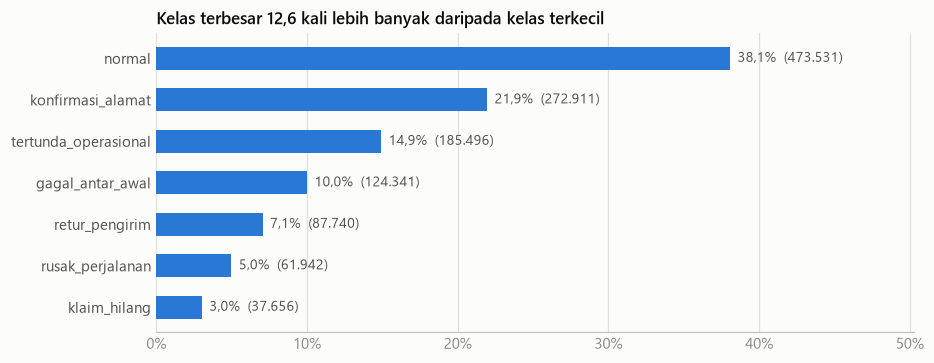

In [6]:
eda = (scan("train", "shipments")
       .join(scan("train", "customers"), on="customer_id", how="left")
       .join(scan("train", "couriers").drop("hub_id"), on="courier_id", how="left")
       .join(scan("train", "hubs").rename({"region": "hub_region"}), on="hub_id", how="left")
       .join(scan("train", "service_packages"), on="package_id", how="left")
       .select(TARGET, "customer_id", "courier_id", "hub_id", "address_quality", "complaint_index", "credit_score", "courier_score",
               "density_index", "automation_level", "declared_value", "distance_km", "ship_month", "fragile_score", "kota_asal", "kota_tujuan",
               "goods_category", "channel", "skor_prioritas_kirim", "indeks_rute_sekunder", "faktor_muatan_internal", "varian_cuaca_rute",
               "indeks_waktu_proses", "skor_kualitas_cek").collect(engine="streaming"))
dist = eda.group_by(TARGET).len().sort("len", descending=True).with_columns((pl.col("len") / pl.col("len").sum()).alias("share"))
fig, ax = plt.subplots(figsize=(8.6, 3.4))
y = np.arange(dist.height)[::-1]
ax.barh(y, dist["share"], height=0.55, color=BLUE)
for yi, s, n in zip(y, dist["share"], dist["len"]):
    ax.text(s + 0.005, yi, f"{idn(s * 100)}%  ({idn(n, 0)})", va="center", fontsize=9, color=INK2)
ax.set_yticks(y, dist[TARGET]); ax.set_xlim(0, dist["share"].max() * 1.32); ax.xaxis.set_major_formatter(pct_axis)
ax.grid(axis="x"); ax.set_axisbelow(True); ax.spines["left"].set_visible(False)
ax.set_title(f"Kelas terbesar {idn(dist['len'][0] / dist['len'][-1])} kali lebih banyak daripada kelas terkecil")
plt.tight_layout(); plt.show()

Karena Macro F1 merata-ratakan F1 tiap kelas, kelas `klaim_hilang` (3%) berbobot sama dengan `normal` (38%). Prediksi dengan probabilitas tertinggi saja akan terlalu jarang memilih kelas kecil, jadi keputusan akhir perlu dikalibrasi per kelas (bagian 7).

### 2.3 Apa yang menggerakkan tiap kelas?

Setiap status punya mekanisme bisnis sendiri. Panel berikut menunjukkan pendorong terkuat untuk enam kelas masalah.

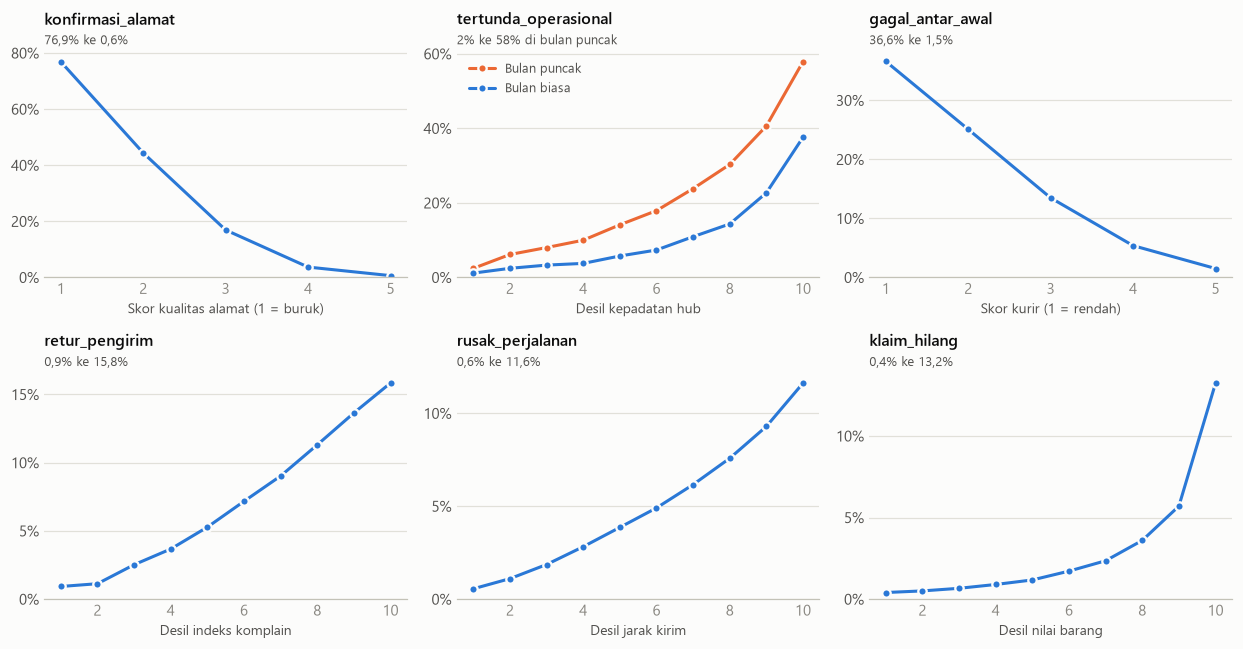

In [7]:
def decile(col):
    return ((pl.col(col).rank("ordinal") - 1) * 10 // pl.col(col).count()).cast(pl.Int8) + 1

def rate(df, key, cls):
    return df.filter(pl.col(key).is_not_null()).group_by(key).agg((pl.col(TARGET) == cls).mean().alias("r")).sort(key)

d = eda.with_columns(decile("density_index").alias("dens"), decile("complaint_index").alias("compl"), decile("distance_km").alias("km"),
                     decile("declared_value").alias("val"), pl.col("ship_month").is_in(PEAK_MONTHS).alias("peak"))
panels = [("konfirmasi_alamat", "address_quality", "Skor kualitas alamat (1 = buruk)"), ("tertunda_operasional", "dens", "Desil kepadatan hub"),
          ("gagal_antar_awal", "courier_score", "Skor kurir (1 = rendah)"), ("retur_pengirim", "compl", "Desil indeks komplain"),
          ("rusak_perjalanan", "km", "Desil jarak kirim"), ("klaim_hilang", "val", "Desil nilai barang")]
fig, axes = plt.subplots(2, 3, figsize=(11.4, 6.0))
for ax, (cls, key, xl) in zip(axes.ravel(), panels):
    if cls == "tertunda_operasional":
        for flag, color, lab in ((True, ORANGE, "Bulan puncak"), (False, BLUE, "Bulan biasa")):
            t = rate(d.filter(pl.col("peak") == flag), key, cls)
            ax.plot(t[key], t["r"], color=color, lw=2, marker="o", ms=5.5, mec=SURFACE, mew=1.5, label=lab, solid_capstyle="round")
        ax.legend(loc="upper left", fontsize=8.5)
        hi = rate(d.filter(pl.col("peak")), key, cls)["r"].to_list()
        sub = f"{idn(hi[0] * 100, 0)}% ke {idn(hi[-1] * 100, 0)}% di bulan puncak"
    else:
        t = rate(d, key, cls)
        ax.plot(t[key], t["r"], color=BLUE, lw=2, marker="o", ms=5.5, mec=SURFACE, mew=1.5, solid_capstyle="round")
        sub = f"{idn(t['r'][0] * 100, 1)}% ke {idn(t['r'][-1] * 100, 1)}%"
    ax.set_title(f"{cls}\n", fontsize=10.5); ax.text(0, 1.03, sub, transform=ax.transAxes, fontsize=8.5, color=INK2)
    ax.set_xlabel(xl, fontsize=9); ax.yaxis.set_major_locator(MaxNLocator(nbins=5, steps=[1, 2, 5, 10])); ax.yaxis.set_major_formatter(pct_axis); ax.set_ylim(bottom=0); ax.grid(axis="y"); ax.set_axisbelow(True); ax.spines["left"].set_visible(False)
plt.tight_layout(); plt.show()

**Bacaan bisnis**

| Status | Pendorong utama | Makna operasional |
|---|---|---|
| `konfirmasi_alamat` | Kualitas alamat, indeks komplain, catatan alamat, percobaan antar berulang | Masalah data alamat pelanggan |
| `tertunda_operasional` | Kepadatan hub, bulan puncak (Maret, Oktober sampai Desember), keterlambatan rute | Penumpukan di hub saat volume tinggi |
| `gagal_antar_awal` | Skor dan pengalaman kurir, kualitas scan, pengiriman malam | Kapabilitas kurir di lapangan |
| `retur_pengirim` | Indeks komplain, COD, riwayat tagihan klaim pelanggan | Perilaku pelanggan |
| `rusak_perjalanan` | Jarak, jumlah segmen, barang rapuh, kualitas kurir | Risiko penanganan sepanjang rute |
| `klaim_hilang` | Nilai barang tinggi, otomasi hub rendah | Kerawanan di hub dengan kontrol lemah |

### 2.4 Kolom yang tidak berguna

Soal menyebut tidak semua kolom berguna. Uji chi-square terhadap target membedakan kolom bersinyal dari kolom noise. Nilai chi²/dof mendekati 1 berarti kolom tersebut tidak lebih informatif daripada angka acak.

In [8]:
def chi_row(col):
    s = eda[col]
    if s.dtype.is_float() and s.n_unique() > 30:
        b = eda.select(decile(col).alias("b"), pl.col(TARGET))
    else:
        b = eda.select(pl.col(col).cast(pl.String).alias("b"), pl.col(TARGET))
    t = b.drop_nulls().group_by("b", TARGET).len().pivot(on=TARGET, index="b", values="len").fill_null(0).drop("b").to_numpy()
    chi, p, dof, _ = chi2_contingency(t)
    return {"kolom": col, "chi2_per_dof": round(chi / dof, 2), "p_value": float(f"{p:.3g}")}
noise = ["skor_prioritas_kirim", "indeks_rute_sekunder", "faktor_muatan_internal", "varian_cuaca_rute", "indeks_waktu_proses", "skor_kualitas_cek", "kota_asal", "kota_tujuan", "goods_category", "channel"]
signal = ["address_quality", "complaint_index", "density_index", "declared_value", "distance_km", "courier_score"]
tb = pl.DataFrame([chi_row(c) for c in noise + signal]).with_columns(pl.when(pl.col("chi2_per_dof") < 2).then(pl.lit("tanpa sinyal")).otherwise(pl.lit("bersinyal")).alias("kesimpulan"))
display(tb.sort("chi2_per_dof"))

kolom,chi2_per_dof,p_value,kesimpulan
str,f64,f64,str
"""goods_category""",0.78,0.799,"""tanpa sinyal"""
"""skor_prioritas_kirim""",0.81,0.835,"""tanpa sinyal"""
"""indeks_rute_sekunder""",0.84,0.795,"""tanpa sinyal"""
"""kota_asal""",0.87,0.939,"""tanpa sinyal"""
"""varian_cuaca_rute""",0.91,0.656,"""tanpa sinyal"""
"""skor_kualitas_cek""",0.96,0.558,"""tanpa sinyal"""
"""kota_tujuan""",1.1,0.138,"""tanpa sinyal"""
"""faktor_muatan_internal""",1.12,0.248,"""tanpa sinyal"""
"""channel""",1.15,0.298,"""tanpa sinyal"""


Enam kolom skor (`skor_prioritas_kirim` sampai `skor_kualitas_cek`) dan kolom kota adalah **noise**. `indeks_waktu_proses` memiliki p = 0,02, tetapi tidak lolos ambang koreksi Bonferroni untuk 10 uji (0,005). `goods_category` dan `channel` juga tanpa sinyal dan tersaring pada tahap seleksi fitur.

Pada eksperimen holdout, membuang kolom noise menaikkan Macro F1 dari 0,5835 menjadi 0,5871 karena model tidak lagi mencari pola palsu pada kolom-kolom tersebut.

### 2.5 Efek tersembunyi per pelanggan, kurir, dan hub

Dua pengiriman dari pelanggan yang sama jauh lebih mungkin berstatus sama. Angka berikut adalah kelipatan peluang: `5,77` berarti jika satu pengiriman pelanggan berstatus retur, pengiriman lain dari pelanggan itu 5,77 kali lebih mungkin retur daripada rata-rata.

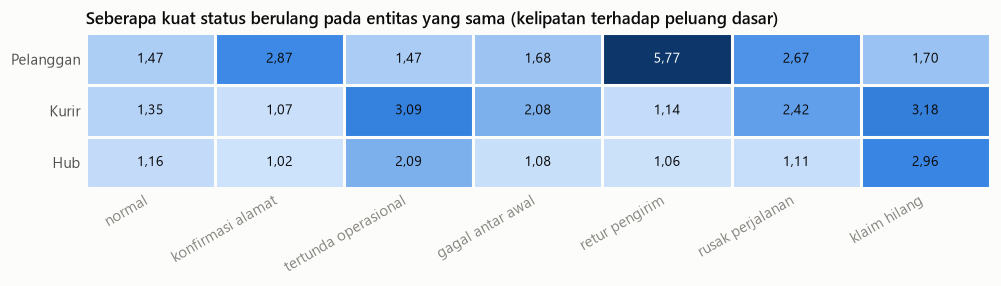

In [9]:
y_all = eda[TARGET].replace_strict(CLASSES, list(range(K)), return_dtype=pl.Int8)
prior_all = np.bincount(y_all.to_numpy(), minlength=K) / eda.height
M = []
for key in ("customer_id", "courier_id", "hub_id"):
    g = pl.DataFrame({"k": eda[key], "y": y_all}).group_by("k", "y").len()
    g = g.join(g.group_by("k").agg(pl.col("len").sum().alias("n")), on="k").filter(pl.col("n") >= 2)
    r = g.group_by("y").agg((pl.col("len") * (pl.col("len") - 1)).sum().alias("same"), (pl.col("len") * (pl.col("n") - 1)).sum().alias("all")).sort("y")
    M.append((r["same"] / r["all"]).to_numpy() / prior_all)
M = np.array(M)
fig, ax = plt.subplots(figsize=(9.2, 2.7))
heatmap(ax, M, [c.replace("_", " ") for c in CLASSES], ["Pelanggan", "Kurir", "Hub"], lambda v: idn(v, 2))
ax.set_title("Seberapa kuat status berulang pada entitas yang sama (kelipatan terhadap peluang dasar)")
plt.tight_layout(); plt.show()

Temuan ini menjadi inti rancangan model:

- **Pelanggan** mewarisi status `retur_pengirim` dan `konfirmasi_alamat`.
- **Kurir** mewarisi `tertunda_operasional`, `klaim_hilang`, `rusak_perjalanan`, dan `gagal_antar_awal`.
- **Hub** mewarisi `klaim_hilang` dan `tertunda_operasional`.

Sebagian efek ini tidak terlihat dari atribut resmi. Contohnya, dua kurir dengan `courier_score` sama bisa berbeda jauh tingkat gagal antarnya. Karena itu model memakai dua hal: **profil entitas tanpa label** (misalnya rata-rata kualitas scan per kurir) dan **target encoding out-of-fold** dari riwayat label entitas tersebut.

### 2.6 Pergeseran antara train dan test

Log operasional di test ternyata sedikit berbeda dari train. Pemeriksaan ini penting agar skor validasi tidak menipu.

In [10]:
def q_ratio(tbl, col):
    qs = np.arange(0.1, 0.91, 0.1)
    a = scan("train", tbl).select([pl.col(col).quantile(float(q)).alias(str(i)) for i, q in enumerate(qs)]).collect(engine="streaming").row(0)
    b = scan("test", tbl).select([pl.col(col).quantile(float(q)).alias(str(i)) for i, q in enumerate(qs)]).collect(engine="streaming").row(0)
    return float(np.median(np.array(b) / np.array(a)))
def m(split, tbl, expr):
    return scan(split, tbl).select(expr.alias("v")).collect(engine="streaming").item()
att = lambda s: scan(s, "scan_events").select((pl.col("event_type") == "upaya_antar").sum()).collect(engine="streaming").item() / scan(s, "shipments").select(pl.len()).collect().item()
rows = [
    {"ukuran": "gap_hours (rasio median test/train)", "train": 1.0, "test": round(q_ratio("scan_events", "gap_hours"), 4)},
    {"ukuran": "durasi_jam (rasio median test/train)", "train": 1.0, "test": round(q_ratio("route_segments", "durasi_jam"), 4)},
    {"ukuran": "rata-rata scan_quality", "train": round(m("train", "scan_events", pl.col("scan_quality").mean()), 4), "test": round(m("test", "scan_events", pl.col("scan_quality").mean()), 4)},
    {"ukuran": "porsi scan manual", "train": round(m("train", "scan_events", pl.col("is_manual").mean()), 4), "test": round(m("test", "scan_events", pl.col("is_manual").mean()), 4)},
    {"ukuran": "upaya antar per pengiriman", "train": round(att("train"), 4), "test": round(att("test"), 4)},
    {"ukuran": "rata-rata days_to_pay", "train": round(m("train", "invoices", pl.col("days_to_pay").mean()), 4), "test": round(m("test", "invoices", pl.col("days_to_pay").mean()), 4)},
    {"ukuran": "porsi pengiriman bulan puncak", "train": round(m("train", "shipments", pl.col("ship_month").is_in(PEAK_MONTHS).mean()), 4), "test": round(m("test", "shipments", pl.col("ship_month").is_in(PEAK_MONTHS).mean()), 4)},
]
display(pl.DataFrame(rows))

ukuran,train,test
str,f64,f64
"""gap_hours (rasio median test/train)""",1.0,1.0272
"""durasi_jam (rasio median test/train)""",1.0,1.0161
"""rata-rata scan_quality""",3.6359,3.5843
"""porsi scan manual""",0.1783,0.1878
"""upaya antar per pengiriman""",1.4917,1.5225
"""rata-rata days_to_pay""",4.2454,4.2555
"""porsi pengiriman bulan puncak""",0.39,0.4185


In [11]:
RUN_DIAGNOSTICS = os.environ.get("RUN_DIAGNOSTICS", "0") == "1"

def run_drift_diagnostics(train_df, test_df, n_fit=600_000, rounds=220):
    """Black-Box Shift Estimation memakai fitur bebas drift, lalu simulasi dampak drift pada holdout berlabel."""
    y = train_df[TARGET].replace_strict(CLASSES, list(range(K)), return_dtype=pl.Int8).to_numpy().astype(np.int64)
    feats = [c for c in test_df.columns if c not in ID_COLS + NOISE_COLS + ["hub_month"]]
    stable_rt = {"rt_n", "rt_n_moda", "rt_km_max", "rt_cost_sum", "rt_moda_first", "rt_moda_last", "rt_longest_share", "rt_cost_per_km", "rt_dur_null"} | {f"rt_{p}_{x}" for p in ("n", "km") for x in MODAS}
    def drifted(c):
        if c.startswith("sc_"): return True
        if c.startswith("rt_"): return c not in stable_rt
        if c.startswith(("cr_sc", "cr_rt", "hb_sc", "hb_rt", "cu_sc", "hm_")): return c != "hm_n"
        return c in {"q_vs_courier", "man_vs_courier", "lgap_vs_hub", "lgap_vs_hubmonth", "lratio_vs_hub", "attempts_vs_customer", "scan_vs_sla", "route_vs_sla", "addr_x_attempts"}
    stable = [c for c in feats if not drifted(c)]
    rs = np.random.RandomState(SEED)
    idx = rs.permutation(len(y)); cut = int(len(y) * 0.75)
    a, b = idx[:cut][:n_fit], idx[cut:]
    P = dict(objective="multiclass", num_class=K, learning_rate=0.08, num_leaves=63, min_data_in_leaf=100, feature_fraction=0.7, bagging_fraction=0.8, bagging_freq=1,
             lambda_l2=5, verbose=-1, num_threads=N_THREADS, cat_smooth=30, max_cat_threshold=16, seed=SEED)
    def fit(cols):
        X = train_df[a].select(pl.col(cols).cast(pl.Float32)).to_numpy()
        return lgb.train(P, lgb.Dataset(X, y[a], feature_name=cols, categorical_feature=[c for c in CAT_COLS if c in cols], free_raw_data=True), rounds)
    def bbse(ps, ys, pt):
        Cm = np.zeros((K, K)); np.add.at(Cm, (ps, ys), 1); Cm /= len(ys)
        return np.linalg.solve(Cm, np.bincount(pt, minlength=K) / len(pt)) * (np.bincount(ys, minlength=K) / len(ys))
    ms = fit(stable)
    Xb, Xt = [d.select(pl.col(stable).cast(pl.Float32)).to_numpy() for d in (train_df[b], test_df)]
    pb, pt = ms.predict(Xb).argmax(1), ms.predict(Xt).argmax(1)
    pi = bbse(pb, y[b], pt)
    se = np.std([bbse(pb, y[b], pt[rs.randint(0, len(pt), len(pt))]) for _ in range(40)], 0)
    mt, me = train_df["ship_month"].to_numpy().astype(int), test_df["ship_month"].to_numpy().astype(int)
    cond = np.array([[(y[mt == mm] == k).mean() for k in range(K)] for mm in range(1, 13)])
    expected = (np.bincount(me, minlength=13)[1:] / len(me)) @ cond
    del ms, Xb, Xt; gc.collect()
    mf = fit(feats)
    Xb = train_df[b].select(pl.col(feats).cast(pl.Float32)).to_numpy()
    Pc = mf.predict(Xb)
    fi = {c: i for i, c in enumerate(feats)}
    Xs = Xb.copy(); RG, RD, DQ, DM = 1.0272, 1.0165, -0.0515, 0.0095
    for c in ["sc_gap_sum", "sc_gap_mean", "sc_gap_med", "sc_gap_max", "sc_gap_min", "sc_gap_std", "sc_gap_first", "sc_gap_last", "sc_gap_U_sum", "sc_gap_U_max", "sc_gap_before_U", "scan_vs_sla"]:
        Xs[:, fi[c]] *= RG
    for c in ["sc_lgap_mean", "lgap_vs_hub", "lgap_vs_hubmonth"]: Xs[:, fi[c]] += np.log(RG) * 0.8
    for c in ["rt_dur_sum", "rt_dur_max", "rt_delay_ratio", "route_vs_sla"]: Xs[:, fi[c]] *= RD
    for c in ["rt_lratio_mean", "rt_lratio_max", "rt_lratio_min", "lratio_vs_hub"]: Xs[:, fi[c]] += np.log(RD)
    Xs[:, fi["rt_speed"]] /= RD
    for c in ["sc_q_mean", "q_vs_courier"]: Xs[:, fi[c]] += DQ
    for c in ["sc_man_rate", "man_vs_courier"]: Xs[:, fi[c]] += DM
    Ps = mf.predict(Xs)
    w, f_clean = optimize_class_weights(Pc, y[b], passes=2)
    f_drift = f1_from_pred(y[b], apply_weights(Ps, w))[0]
    out = dict(classes=CLASSES, train_share=(np.bincount(y, minlength=K) / len(y)).tolist(), expected_from_month=expected.tolist(), bbse_test=pi.tolist(), bbse_se=se.tolist(),
               f1_clean=f_clean, f1_simulated_drift=f_drift, n_features_stable=len(stable), n_features_all=len(feats))
    (MODEL_DIR / "drift_diagnostics.json").write_text(json.dumps(out, indent=2))
    return out

if RUN_DIAGNOSTICS:
    _tr, _te, _ = build_features(meta=json.loads((MODEL_DIR / "feature_config.json").read_text())["meta"], verbose=False)
    run_drift_diagnostics(_tr, _te); del _tr, _te; gc.collect()
drift = json.loads((MODEL_DIR / "drift_diagnostics.json").read_text())
display(pl.DataFrame({"kelas": drift["classes"], "porsi_train_%": np.round(np.array(drift["train_share"]) * 100, 2), "harapan_dari_bulan_%": np.round(np.array(drift["expected_from_month"]) * 100, 2),
                      "estimasi_test_%": np.round(np.array(drift["bbse_test"]) * 100, 2), "galat_baku_%": np.round(np.array(drift["bbse_se"]) * 100, 2)}))
print(f"Simulasi drift pada holdout berlabel: Macro F1 bersih = {drift['f1_clean']:.4f}, dengan drift tanpa koreksi = {drift['f1_simulated_drift']:.4f}")

kelas,porsi_train_%,harapan_dari_bulan_%,estimasi_test_%,galat_baku_%
str,f64,f64,f64,f64
"""normal""",38.08,37.85,37.71,0.11
"""konfirmasi_alamat""",21.94,21.93,21.83,0.14
"""tertunda_operasional""",14.92,15.21,15.49,0.11
"""gagal_antar_awal""",10.0,9.98,9.95,0.21
"""retur_pengirim""",7.06,7.05,7.07,0.12
"""rusak_perjalanan""",4.98,4.97,5.06,0.15
"""klaim_hilang""",3.03,3.02,2.88,0.07


Simulasi drift pada holdout berlabel: Macro F1 bersih = 0.5908, dengan drift tanpa koreksi = 0.5914


**Kesimpulan drift**

- `gap_hours`, `durasi_jam`, kualitas scan, dan porsi scan manual bergeser **seragam** di semua hub dan kurir. Kolom tagihan tidak bergeser.
- Komposisi kelas test diestimasi dengan *Black-Box Shift Estimation* memakai fitur yang bebas drift. Hasilnya dekat dengan yang diharapkan dari perubahan porsi bulan saja. Selisih terbesar ada di `tertunda_operasional`, yaitu 0,28 poin persen (2,5 galat baku).
- Simulasi menerapkan drift yang sama ke data berlabel. Pada model diagnostik, Macro F1 tidak turun (0,5908 tanpa drift, 0,5914 dengan drift), jadi **koreksi drift tidak ditambahkan** agar pipeline tetap sederhana.

## 3. Rancangan preprocessing dan fitur

| Langkah | Keputusan | Alasan |
|---|---|---|
| Penggabungan | 4 tabel fakta diringkas per `shipment_id`, 5 tabel dimensi di-*left join* | Satu baris per pengiriman, tanpa menggandakan baris |
| Nilai kosong | Dibiarkan NaN untuk model pohon, median untuk regresi logistik | Model pohon dapat memakai pola kekosongan (misalnya durasi rute), regresi logistik butuh nilai lengkap |
| Kolom noise | Enam skor dan kota dibuang | Tidak lolos uji chi-square |
| Delay | Rasio durasi aktual terhadap kecepatan normal tiap moda | Membandingkan darat, laut, dan udara secara adil |
| Profil entitas | Rata-rata perilaku per kurir, hub, pelanggan dari train dan test **tanpa label** | Menangkap kemampuan kurir dan kepadatan hub yang tidak tercatat |
| Fitur bisnis | Bulan puncak, jam malam, keterlambatan bayar, tekanan SLA, interaksi risiko | Menerjemahkan proses bisnis menjadi sinyal |

### 3.1 Ringkasan per tabel

In [12]:
def read_table(split, name):
    if name in ("customers", "couriers", "hubs", "service_packages", "promotions"):
        split = "train"  # kelima tabel dimensi identik di folder train dan test (sudah diverifikasi dengan MD5)
    return pl.scan_csv(DATA_DIR / split / f"{name}.csv", infer_schema_length=200_000)


def safe_div(a, b):
    return pl.when(b.is_not_null() & (b != 0)).then(a / b).otherwise(None)


def fe_scan(lf):
    """Log pemindaian -> ringkasan per pengiriman: jumlah peristiwa, jeda, kualitas scan, urutan."""
    lf = lf.select("shipment_id", "event_type", "gap_hours", "device_type", "scan_quality", "is_manual")
    lf = lf.with_columns(pl.col("gap_hours").log1p().alias("lg"))
    e, g, lg, q, m, d = [pl.col(c) for c in ("event_type", "gap_hours", "lg", "scan_quality", "is_manual", "device_type")]
    isu = e == "upaya_antar"
    cumu = isu.cast(pl.Int32).cum_sum()
    aggs = [pl.len().alias("sc_n")]
    aggs += [(e == ev).sum().alias(f"sc_n_{ev}") for ev in EVENTS]
    aggs += [g.sum().alias("sc_gap_sum"), g.mean().alias("sc_gap_mean"), g.median().alias("sc_gap_med"),
             g.max().alias("sc_gap_max"), g.min().alias("sc_gap_min"), g.std().alias("sc_gap_std"),
             lg.mean().alias("sc_lgap_mean"), lg.std().alias("sc_lgap_std"),
             g.first().alias("sc_gap_first"), g.last().alias("sc_gap_last"), g.arg_max().alias("sc_gap_argmax"),
             q.mean().alias("sc_q_mean"), q.min().alias("sc_q_min"), q.max().alias("sc_q_max"), q.std().alias("sc_q_std"),
             (q <= 2).sum().alias("sc_q_low_n"), (q == 5).sum().alias("sc_q_top_n"),
             m.sum().alias("sc_man_n"), m.mean().alias("sc_man_rate"),
             (isu & isu.shift(1).fill_null(False)).sum().alias("sc_UU"),
             ((e == "pickup") & (cumu.shift(1).fill_null(0) > 0)).sum().alias("sc_repickup"),
             g.filter(isu).sum().alias("sc_gap_U_sum"), g.filter(isu).max().alias("sc_gap_U_max"),
             g.filter(cumu == 0).sum().alias("sc_gap_before_U")]
    aggs += [(d == x).mean().alias(f"sc_dev_{x}") for x in DEVICES]
    return lf.group_by("shipment_id").agg(aggs)


def nominal_speeds():
    """Kecepatan median tiap moda: acuan untuk mengukur keterlambatan rute."""
    r = pl.concat([read_table(s, "route_segments").select("moda", "jarak_segmen_km", "durasi_jam") for s in ("train", "test")])
    out = (r.filter(pl.col("durasi_jam") > 0).with_columns((pl.col("jarak_segmen_km") / pl.col("durasi_jam")).alias("v"))
           .group_by("moda").agg(pl.col("v").median()).collect(engine="streaming"))
    return dict(zip(out["moda"].to_list(), out["v"].to_list()))


def fe_route(lf, vmoda):
    """Kaki rute -> jumlah segmen, moda, biaya, dan rasio durasi aktual terhadap durasi normal moda."""
    lf = lf.select("shipment_id", "urutan", "moda", "jarak_segmen_km", "durasi_jam", "biaya_segmen").sort("shipment_id", "urutan")
    lf = lf.with_columns(pl.col("moda").replace_strict(vmoda, return_dtype=pl.Float64).alias("v"))
    lf = lf.with_columns((pl.col("jarak_segmen_km") / pl.col("v")).alias("exp_dur"))
    lf = lf.with_columns(
        pl.when(pl.col("durasi_jam") > 0).then((pl.col("durasi_jam") / pl.col("exp_dur")).log()).otherwise(None).alias("lratio"),
        pl.when(pl.col("durasi_jam").is_not_null()).then(pl.col("exp_dur")).otherwise(None).alias("exp_dur_ok"))
    km, dur, cost, md, lr = [pl.col(c) for c in ("jarak_segmen_km", "durasi_jam", "biaya_segmen", "moda", "lratio")]
    aggs = [pl.len().alias("rt_n"), md.n_unique().alias("rt_n_moda"), km.max().alias("rt_km_max"),
            dur.sum().alias("rt_dur_sum"), dur.max().alias("rt_dur_max"), dur.null_count().alias("rt_dur_null"),
            pl.col("exp_dur_ok").sum().alias("rt_exp_dur"), lr.mean().alias("rt_lratio_mean"), lr.max().alias("rt_lratio_max"),
            lr.min().alias("rt_lratio_min"), cost.sum().alias("rt_cost_sum"), md.first().alias("rt_moda_first"), md.last().alias("rt_moda_last")]
    for x in MODAS:
        aggs += [(md == x).sum().alias(f"rt_n_{x}"), km.filter(md == x).sum().alias(f"rt_km_{x}")]
    return lf.group_by("shipment_id").agg(aggs)


def fe_invoice(lf):
    """Tagihan -> nilai per jenis tagihan, lama pembayaran, status, dan penalti."""
    t, amt, dsc, tax, dtp, st, pen, im, pm = [pl.col(c) for c in ("invoice_type", "amount", "discount", "tax", "days_to_pay",
                                                                  "payment_status", "is_penalty", "issued_month", "payment_method")]
    aggs = [pl.len().alias("inv_n"), amt.sum().alias("inv_amt_sum"), dsc.sum().alias("inv_disc_sum"), tax.sum().alias("inv_tax_sum"),
            dtp.max().alias("inv_dtp_max"), dtp.mean().alias("inv_dtp_mean"), dtp.min().alias("inv_dtp_min"), (dtp >= 15).sum().alias("inv_dtp15_n"),
            (st == "gagal").sum().alias("inv_st_gagal"), (st == "tertunda").sum().alias("inv_st_tunda"), pen.max().alias("inv_penalty"),
            im.max().alias("inv_month_max"), im.min().alias("inv_month_min"), (pm == "cod").sum().alias("inv_pm_cod"), pm.first().alias("inv_pm_first")]
    for x in INV_TYPES:
        k = t == x
        aggs += [k.sum().alias(f"inv_has_{x}"), amt.filter(k).sum().alias(f"inv_amt_{x}"), dtp.filter(k).max().alias(f"inv_dtp_{x}"),
                 im.filter(k).max().alias(f"inv_month_{x}")]
    return lf.group_by("shipment_id").agg(aggs)


def join_dims(ship):
    cu = read_table("train", "customers")
    co = read_table("train", "couriers").drop("hub_id")
    hb = read_table("train", "hubs").rename({"region": "hub_region"})
    pk = read_table("train", "service_packages")
    pr = read_table("train", "promotions")
    return (ship.join(cu, on="customer_id", how="left").join(co, on="courier_id", how="left").join(hb, on="hub_id", how="left")
            .join(pk, on="package_id", how="left").join(pr, on="promo_id", how="left"))

### 3.2 Fitur bisnis

In [13]:
def fe_derived(lf):
    """Fitur bisnis level baris: musim puncak, jam malam, tekanan SLA, keterlambatan rute, interaksi risiko."""
    c = pl.col
    lf = lf.with_columns(
        c("declared_value").log1p().alias("log_value"),
        c("distance_km").log1p().alias("log_km"),
        safe_div(c("declared_value"), c("weight_kg")).log1p().alias("log_value_per_kg"),
        safe_div(c("weight_kg"), c("max_weight_kg")).alias("w_over_pkg"),
        safe_div(c("weight_kg"), c("kapasitas_muatan_kg")).alias("w_over_vehicle"),
        pl.max_horizontal("weight_kg", "berat_volumetrik").alias("chargeable_kg"),
        safe_div(c("volume_l"), c("weight_kg")).alias("vol_per_kg"),
        c("ship_month").is_in(PEAK_MONTHS).cast(pl.Int8).alias("is_peak_month"),
        (c("ship_dow") >= 5).cast(pl.Int8).alias("is_weekend"),
        ((c("ship_hour") < 6) | (c("ship_hour") >= 20)).cast(pl.Int8).alias("is_night"),
        ((c("ship_hour") < c("jam_buka")) | (c("ship_hour") >= c("jam_tutup"))).cast(pl.Int8).alias("out_of_hours"),
        (c("jam_tutup") - c("jam_buka")).alias("hub_open_hours"),
        (c("ship_hour") - c("jam_buka")).alias("hours_since_open"),
        (c("jam_tutup") - c("ship_hour")).alias("hours_to_close"),
        (c("promo_id") != "TANPA_PROMO").cast(pl.Int8).alias("has_promo"),
        ((c("is_promo") == 1) & (((c("bulan_mulai") <= c("bulan_akhir")) & (c("ship_month") >= c("bulan_mulai")) & (c("ship_month") <= c("bulan_akhir")))
                                 | ((c("bulan_mulai") > c("bulan_akhir")) & ((c("ship_month") >= c("bulan_mulai")) | (c("ship_month") <= c("bulan_akhir")))))).cast(pl.Int8).alias("promo_in_window"),
        (c("region") == c("dest_region")).cast(pl.Int8).alias("dest_is_home"),
        (c("hub_region") == c("dest_region")).cast(pl.Int8).alias("dest_is_hub_region"),
        (c("kota_asal") == c("kota_tujuan")).cast(pl.Int8).alias("same_city"),
        (c("estimasi_hari") * 24).alias("sla_hours"),
        safe_div(c("rt_dur_sum"), c("rt_exp_dur")).alias("rt_delay_ratio"),
        safe_div(c("distance_km"), c("rt_dur_sum")).alias("rt_speed"),
        safe_div(c("rt_cost_sum"), c("distance_km")).alias("rt_cost_per_km"),
        safe_div(c("rt_km_max"), c("distance_km")).alias("rt_longest_share"),
        ((c("inv_month_max") - c("ship_month")) % 12).alias("inv_month_lag"),
        ((c("inv_month_klaim") - c("ship_month")) % 12).alias("klaim_month_lag"),
        safe_div(c("inv_amt_klaim").cast(pl.Float64), c("declared_value")).alias("klaim_to_value"),
        safe_div(c("inv_disc_sum"), c("inv_amt_sum")).alias("inv_disc_rate"),
        (c("inv_dtp_max") >= 15).cast(pl.Int8).alias("inv_late15"),
        safe_div(c("sc_n_upaya_antar").cast(pl.Float64), c("sc_n")).alias("sc_share_U"),
        safe_div(c("sc_gap_before_U"), c("sc_gap_sum")).alias("sc_share_before_U"),
        safe_div(c("sc_gap_max"), c("sc_gap_sum")).alias("sc_gap_max_share"),
    )
    return lf.with_columns(
        safe_div(c("sc_gap_sum"), c("sla_hours")).alias("scan_vs_sla"),
        safe_div(c("rt_dur_sum"), c("sla_hours")).alias("route_vs_sla"),
        (c("is_peak_month") * c("density_index")).alias("peak_x_density"),
        (c("density_index") * c("capacity_index")).alias("density_x_capacity"),
        (c("fragile_score") * c("log_km")).alias("fragile_x_km"),
        (c("fragile_score") * c("rt_n")).alias("fragile_x_segments"),
        (c("log_value") * (6 - c("automation_level"))).alias("value_x_lowauto"),
        ((6 - c("address_quality")) * c("complaint_index")).alias("addr_x_complaint"),
        (c("is_cod") * c("complaint_index")).alias("cod_x_complaint"),
        ((6 - c("address_quality")) * (c("jumlah_catatan") > 0).cast(pl.Int8)).alias("addr_x_notes"),
        ((6 - c("address_quality")) * c("flag_alamat_baru")).alias("addr_x_newaddr"),
        ((6 - c("address_quality")) * c("sc_n_upaya_antar")).alias("addr_x_attempts"),
    )


ENTITY_SPECS = {
    "courier_id": ("cr", ["sc_q_mean", "sc_man_rate", "sc_lgap_mean", "sc_n_upaya_antar", "sc_n", "rt_lratio_mean", "inv_dtp_mean"]),
    "hub_id": ("hb", ["sc_lgap_mean", "rt_lratio_mean", "sc_q_mean", "sc_man_rate", "inv_dtp_mean", "inv_late15"]),
    "customer_id": ("cu", ["sc_n_upaya_antar", "sc_lgap_mean", "inv_dtp_mean", "inv_has_klaim", "jumlah_catatan", "flag_alamat_baru", "is_cod", "sc_q_mean"]),
}

### 3.3 Penggabungan seluruh tabel

In [14]:
def build_features(meta=None, verbose=True):
    """Menggabungkan 9 tabel menjadi satu baris per pengiriman. Profil entitas dihitung dari train+test TANPA label."""
    t0 = time.time()
    vmoda = meta["vmoda"] if meta else nominal_speeds()
    frames = {}
    for split in ("train", "test"):
        sc = fe_scan(read_table(split, "scan_events")).collect()
        rt = fe_route(read_table(split, "route_segments"), vmoda).collect()
        iv = fe_invoice(read_table(split, "invoices")).collect()
        df = (join_dims(read_table(split, "shipments")).collect(engine="streaming")
              .join(sc, on="shipment_id", how="left").join(rt, on="shipment_id", how="left").join(iv, on="shipment_id", how="left"))
        del sc, rt, iv; gc.collect()
        frames[split] = fe_derived(df.lazy()).collect()
        if verbose: print(f"  {split}: {frames[split].shape}  ({time.time() - t0:.0f}s)", flush=True)
    keys = ["shipment_id", "customer_id", "courier_id", "hub_id", "ship_month"]
    need = sorted({c for _, cc in ENTITY_SPECS.values() for c in cc})
    allv = pl.concat([frames[s].select(keys + need) for s in ("train", "test")])
    ents = {k: allv.group_by(k).agg([pl.len().alias(f"{p}_n")] + [pl.col(c).mean().alias(f"{p}_{c}") for c in cc]) for k, (p, cc) in ENTITY_SPECS.items()}
    hm = allv.group_by("hub_id", "ship_month").agg(pl.len().alias("hm_n"), pl.col("sc_lgap_mean").mean().alias("hm_lgap"), pl.col("rt_lratio_mean").mean().alias("hm_lratio"))
    del allv; gc.collect()
    if meta:
        cat_maps = meta["cat_maps"]
    else:
        cat_maps = {c: sorted(x for x in set(frames["train"][c].unique().to_list()) | set(frames["test"][c].unique().to_list()) if x is not None) for c in CAT_COLS}
    out = {}
    for split in ("train", "test"):
        df = frames.pop(split)
        for k, e in ents.items():
            df = df.join(e, on=k, how="left")
        df = df.join(hm, on=["hub_id", "ship_month"], how="left")
        df = df.with_columns(
            (pl.col("sc_q_mean") - pl.col("cr_sc_q_mean")).alias("q_vs_courier"),
            (pl.col("sc_man_rate") - pl.col("cr_sc_man_rate")).alias("man_vs_courier"),
            (pl.col("sc_lgap_mean") - pl.col("hb_sc_lgap_mean")).alias("lgap_vs_hub"),
            (pl.col("sc_lgap_mean") - pl.col("hm_lgap")).alias("lgap_vs_hubmonth"),
            (pl.col("rt_lratio_mean") - pl.col("hb_rt_lratio_mean")).alias("lratio_vs_hub"),
            (pl.col("sc_n_upaya_antar") - pl.col("cu_sc_n_upaya_antar")).alias("attempts_vs_customer"),
        )
        df = df.with_columns([pl.col(c).replace_strict(m, list(range(len(m))), default=-1, return_dtype=pl.Int16).alias(c) for c, m in cat_maps.items()])
        df = df.drop("bulan_mulai", "bulan_akhir")
        num = [c for c, t in df.schema.items() if t.is_numeric() and c not in CAT_COLS]
        df = df.with_columns([pl.col(c).cast(pl.Float32) for c in num])
        df = df.with_columns((pl.col("hub_id") + "_" + pl.col("ship_month").cast(pl.Int8).cast(pl.String)).alias("hub_month"))
        out[split] = df.sort("shipment_id")
        del df; gc.collect()
    if verbose: print(f"  fitur selesai: train {out['train'].shape}, test {out['test'].shape} ({time.time() - t0:.0f}s)", flush=True)
    return out["train"], out["test"], {"vmoda": vmoda, "cat_maps": cat_maps}

## 4. Validasi dan pencegahan kebocoran

Target encoding mudah membocorkan label, jadi aturannya ketat:

1. **Validasi luar:** `StratifiedKFold` 5 lipatan. Baris validasi tidak pernah dipakai untuk melatih apa pun pada fold-nya.
2. **Target encoding dalam:** baris latih dienkode dari 10 lipatan dalam, sehingga label sebuah baris tidak pernah masuk ke fiturnya sendiri.
3. **Stacking:** logit regresi logistik untuk baris latih selalu berasal dari model yang tidak melihat baris tersebut.
4. **Profil entitas** hanya memakai kolom masukan, tidak pernah memakai label.
5. **Bobot keputusan per kelas** dinilai secara *cross-fitted*: dipelajari dari 4 fold, diuji pada fold kelima.

In [15]:
def f1_from_pred(y, pred):
    cm = np.bincount(y.astype(np.int64) * K + pred.astype(np.int64), minlength=K * K).reshape(K, K)
    tp = np.diag(cm).astype(np.float64)
    fp, fn = cm.sum(0) - tp, cm.sum(1) - tp
    f = np.divide(2 * tp, 2 * tp + fp + fn, out=np.zeros(K), where=(2 * tp + fp + fn) > 0)
    return float(f.mean()), f


def apply_weights(P, w):
    return (np.log(np.clip(P, 1e-9, 1)) + np.log(w)).argmax(1)


def optimize_class_weights(P, y, passes=3, grid=None, w0=None):
    """Coordinate ascent pada pengali probabilitas per kelas untuk memaksimalkan Macro F1."""
    grid = np.round(np.arange(0.6, 3.51, 0.05), 3) if grid is None else grid
    lp = np.log(np.clip(P, 1e-9, 1)).astype(np.float32)
    w = np.zeros(K, dtype=np.float32) if w0 is None else np.log(w0).astype(np.float32)
    best, _ = f1_from_pred(y, (lp + w).argmax(1))
    for _ in range(passes):
        improved = False
        for c in range(1, K):  # kelas normal menjadi acuan
            cur, bv, bs = w[c], w[c], best
            others = lp + w; others[:, c] = -np.inf
            om, oa = others.max(1), others.argmax(1)
            for g in np.log(grid).astype(np.float32):
                s, _ = f1_from_pred(y, np.where(lp[:, c] + g > om, c, oa))
                if s > bs + 1e-6: bs, bv = s, g
            if bv != cur: w[c], best, improved = bv, bs, True
        if not improved: break
    return np.exp(w).astype(np.float64), best


def softmax(L):
    L = L - L.max(1, keepdims=True)
    P = np.exp(L)
    return P / P.sum(1, keepdims=True)

In [16]:
def te_oof(codes, y, n_cat, prior, alpha, folds):
    """Target encoding K-fold: tiap baris hanya dienkode dari label baris pada fold lain."""
    C = np.zeros((n_cat, K), dtype=np.int32)
    np.add.at(C, (codes, y), 1)
    out = np.zeros((len(codes), K + 1), dtype=np.float32)
    for f in range(int(folds.max()) + 1):
        m = folds == f
        Cf = np.zeros((n_cat, K), dtype=np.int32)
        np.add.at(Cf, (codes[m], y[m]), 1)
        rest = C[codes[m]] - Cf[codes[m]]
        n = rest.sum(1, keepdims=True)
        out[m, :K] = (rest + alpha * prior) / (n + alpha)
        out[m, K] = n[:, 0]
    return out, C


def te_apply(C, codes, prior, alpha):
    n = C[codes].sum(1, keepdims=True)
    return np.hstack([(C[codes] + alpha * prior) / (n + alpha), n]).astype(np.float32)


def te_tables_fit(df, y):
    d = df.select("customer_id", "courier_id", "hub_id", "hub_month").with_columns(pl.Series("__y", y))
    return {key: d.group_by(key).agg([(pl.col("__y") == k).sum().cast(pl.UInt32).alias(f"c{k}") for k in range(K)]) for key, _, _ in TE_ENTITIES}


def te_lookup(df, tables, prior):
    """Encoding baris test dari seluruh label train."""
    cols = [f"c{k}" for k in range(K)]
    out = []
    for key, _, alpha in TE_ENTITIES:
        j = df.select(key).join(tables[key], on=key, how="left", maintain_order="left").select(cols).fill_null(0).to_numpy().astype(np.float64)
        n = j.sum(1, keepdims=True)
        out.append(np.hstack([(j + alpha * prior) / (n + alpha), n]).astype(np.float32))
    return np.hstack(out)


def glm_scaler(X, seed=SEED):
    rs = np.random.RandomState(seed)
    s = X[rs.choice(len(X), min(200_000, len(X)), replace=False)]
    lo, med, hi = np.nanpercentile(s, [0.5, 50, 99.5], axis=0)
    s = np.clip(np.where(np.isnan(s), med, s), lo, hi)
    mu, sd = s.mean(0), s.std(0) + 1e-6
    return dict(lo=lo.astype(np.float32), med=med.astype(np.float32), hi=hi.astype(np.float32),
                mu=mu.astype(np.float32), sd=sd.astype(np.float32), keep=sd > 1e-5)


def glm_transform(X, st, chunk=200_000):
    keep = st["keep"]
    out = np.empty((len(X), int(keep.sum())), dtype=np.float32)
    for i in range(0, len(X), chunk):
        b = X[i:i + chunk]
        b = np.clip(np.where(np.isnan(b), st["med"], b), st["lo"], st["hi"])
        out[i:i + chunk] = ((b - st["mu"]) / st["sd"])[:, keep]
    return out


def glm_logits(Z, coef, intercept, chunk=200_000):
    out = np.empty((len(Z), K), dtype=np.float32)
    for i in range(0, len(Z), chunk):
        out[i:i + chunk] = Z[i:i + chunk] @ coef.T + intercept
    return out

## 5. Seleksi fitur dan tuning

**Seleksi fitur.** Sepuluh kolom acak ditambahkan sebagai pembanding, lalu setiap fitur diacak satu per satu pada holdout. Fitur yang dampaknya tidak melebihi kolom acak dibuang. Dari 264 kandidat tersisa 70 fitur, dan log loss holdout membaik dari 0,79601 menjadi 0,79425.

**Tuning.** Optuna (TPE, 28 percobaan) menemukan bahwa pohon kecil dengan regularisasi kuat bekerja paling baik: 15 daun dan minimum 2.422 baris per daun. Ini sejalan dengan temuan bahwa pola data cenderung aditif.

Daftar fitur dan parameter di sel konfigurasi berasal dari eksperimen tersebut. Kode prosedurnya disertakan di bawah dan dinonaktifkan secara default. Hasil pengulangan bisa sedikit berbeda karena ada unsur acak.

In [17]:
RUN_SELECTION = os.environ.get("RUN_SELECTION", "0") == "1"
RUN_TUNING = os.environ.get("RUN_TUNING", "0") == "1"

def prepare_holdout(train_df, n_fit=500_000):
    y = train_df[TARGET].replace_strict(CLASSES, list(range(K)), return_dtype=pl.Int8).to_numpy().astype(np.int64)
    base = [c for c in train_df.columns if c not in ID_COLS + NOISE_COLS + ["hub_month", TARGET]]
    glm_num = [i for i, c in enumerate(base) if c not in CAT_COLS]
    dev, val = next(StratifiedKFold(5, shuffle=True, random_state=SEED).split(np.zeros(len(y)), y))
    prior = np.bincount(y[dev], minlength=K) / len(dev)
    inner = np.zeros(len(dev), dtype=np.int8)
    for i, (_, b) in enumerate(StratifiedKFold(5, shuffle=True, random_state=7).split(np.zeros(len(dev)), y[dev])):
        inner[b] = i
    Td, Tv = [], []
    for key, _, alpha in TE_ENTITIES:
        cd = (train_df[key].rank("dense").cast(pl.Int32) - 1).to_numpy()
        oof, C = te_oof(cd[dev], y[dev], int(cd.max()) + 1, prior, alpha, inner)
        Td.append(oof); Tv.append(te_apply(C, cd[val], prior, alpha))
    sub = np.random.RandomState(SEED).choice(len(dev), min(n_fit, len(dev)), replace=False)
    Tt, Tv = np.hstack(Td)[sub], np.hstack(Tv)
    Xb = train_df.select(pl.col(base).cast(pl.Float32)).to_numpy()
    Xt, Xv, yt, yv = Xb[dev[sub]], Xb[val], y[dev[sub]], y[val]; del Xb
    st = glm_scaler(np.hstack([Xt[:, glm_num], Tt]))
    Zt, Zv = glm_transform(np.hstack([Xt[:, glm_num], Tt]), st), glm_transform(np.hstack([Xv[:, glm_num], Tv]), st)
    Gt, Gv = np.zeros((len(yt), K), dtype=np.float32), np.zeros((len(yv), K), dtype=np.float32)
    for a, b in StratifiedKFold(2, shuffle=True, random_state=3).split(Zt, yt):
        m_ = LogisticRegression(C=GLM_C, max_iter=GLM_ITERS, tol=1e-3).fit(Zt[a], yt[a])
        Gt[b] = m_.decision_function(Zt[b]); Gv += m_.decision_function(Zv) / 2
    return dict(base=base, Xt=Xt, Xv=Xv, Tt=Tt, Tv=Tv, Gt=Gt, Gv=Gv, yt=yt, yv=yv)

def run_feature_selection(train_df, n_fit=500_000, n_perm=120_000, n_shadow=10):
    h = prepare_holdout(train_df, n_fit)
    rs = np.random.RandomState(SEED)
    shadows = [f"shadow_{i}" for i in range(n_shadow)]
    names = h["base"] + TE_NAMES + GLM_NAMES + shadows
    Xt = np.hstack([h["Xt"], h["Tt"], h["Gt"], rs.rand(len(h["yt"]), n_shadow).astype(np.float32)])
    Xv = np.hstack([h["Xv"], h["Tv"], h["Gv"], rs.rand(len(h["yv"]), n_shadow).astype(np.float32)])
    params = {**LGB_PARAMS, "learning_rate": 0.08, "num_leaves": 63, "min_data_in_leaf": 100, "feature_fraction": 0.6, "bagging_fraction": 0.8, "lambda_l1": 0.0, "lambda_l2": 5.0, "min_gain_to_split": 0.0, "path_smooth": 0.0}
    dt = lgb.Dataset(Xt, h["yt"], feature_name=names, categorical_feature=[c for c in CAT_COLS if c in names], free_raw_data=True)
    booster = lgb.train(params, dt, 500, valid_sets=[lgb.Dataset(Xv, h["yv"], reference=dt)], callbacks=[lgb.early_stopping(25, verbose=False)])
    pick = rs.choice(len(h["yv"]), min(n_perm, len(h["yv"])), replace=False); Xp, yp = Xv[pick].copy(), h["yv"][pick]
    ref = log_loss(yp, booster.predict(Xp), labels=list(range(K)))
    imp = {}
    for j, n in enumerate(names):
        keep = Xp[:, j].copy(); Xp[:, j] = rs.permutation(keep)
        imp[n] = log_loss(yp, booster.predict(Xp), labels=list(range(K))) - ref
        Xp[:, j] = keep
    sh = np.array([imp[n] for n in shadows]); floor = max(sh.max(), sh.mean() + 3 * sh.std())
    return dict(floor=float(floor), rank=sorted(((n, float(v)) for n, v in imp.items() if n not in shadows), key=lambda x: -x[1]))

def run_tuning(train_df, n_fit=500_000, n_trials=28, timeout=1800):
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    h = prepare_holdout(train_df, n_fit)
    tei = [TE_NAMES.index(c) for c in STACK_TE]; bi = [h["base"].index(c) for c in STACK_BASE]
    Xt, Xv = [np.hstack([h[f"X{s}"][:, bi], h[f"T{s}"][:, tei], h[f"G{s}"]]) for s in "tv"]
    names = STACK_BASE + STACK_TE + GLM_NAMES
    dt = lgb.Dataset(Xt, h["yt"], feature_name=names, categorical_feature=STACK_CATS, free_raw_data=False)
    dv = lgb.Dataset(Xv, h["yv"], reference=dt, free_raw_data=False)
    fixed = dict(objective="multiclass", num_class=K, metric="multi_logloss", learning_rate=0.08, verbose=-1, num_threads=N_THREADS, bagging_freq=1, max_bin=255,
                 cat_smooth=30, min_data_per_group=200, max_cat_threshold=16, feature_pre_filter=False)
    def objective(t):
        p = dict(fixed, num_leaves=t.suggest_int("num_leaves", 15, 127, log=True), min_data_in_leaf=t.suggest_int("min_data_in_leaf", 50, 3000, log=True),
                 feature_fraction=t.suggest_float("feature_fraction", 0.35, 0.95), bagging_fraction=t.suggest_float("bagging_fraction", 0.5, 0.95),
                 lambda_l1=t.suggest_float("lambda_l1", 1e-3, 10, log=True), lambda_l2=t.suggest_float("lambda_l2", 1e-2, 100, log=True),
                 min_gain_to_split=t.suggest_float("min_gain_to_split", 1e-3, 3, log=True), path_smooth=t.suggest_float("path_smooth", 1e-2, 100, log=True))
        return lgb.train(p, dt, 450, valid_sets=[dv], callbacks=[lgb.early_stopping(20, verbose=False)]).best_score["valid_0"]["multi_logloss"]
    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED, multivariate=True))
    study.optimize(objective, n_trials=n_trials, timeout=timeout)
    return dict(params=study.best_params, logloss=study.best_value, trials=len(study.trials))

if RUN_SELECTION or RUN_TUNING:
    _tr, _, _ = build_features(meta=json.loads((MODEL_DIR / "feature_config.json").read_text())["meta"], verbose=False)
    if RUN_SELECTION: (MODEL_DIR / "feature_selection.json").write_text(json.dumps(run_feature_selection(_tr)))
    if RUN_TUNING: (MODEL_DIR / "tuning_result.json").write_text(json.dumps(run_tuning(_tr), indent=2))
    del _tr; gc.collect()

sel = json.loads((MODEL_DIR / "feature_selection.json").read_text())
kept = sum(v > sel["floor"] for _, v in sel["rank"])
print(f"Ambang noise (kolom acak): {sel['floor']:.6f} | fitur lolos: {kept} dari {len(sel['rank'])}")
display(pl.DataFrame({"fitur": [n for n, _ in sel["rank"][:15]], "kenaikan_logloss_bila_diacak": [round(v, 5) for _, v in sel["rank"][:15]]}))
tuned = json.loads((MODEL_DIR / "tuning_result.json").read_text())
print(f"Hasil tuning: log loss holdout terbaik {tuned['logloss']:.5f}")
display(pl.DataFrame({"parameter": list(tuned["params"]), "nilai": [round(float(v), 5) for v in tuned["params"].values()]}))

Ambang noise (kolom acak): 0.000099 | fitur lolos: 70 dari 264


fitur,kenaikan_logloss_bila_diacak
str,f64
"""glm_normal""",0.36285
"""glm_tertun""",0.19937
"""glm_konfir""",0.17503
"""glm_retur_""",0.08481
"""glm_gagal_""",0.04271
"""glm_klaim_""",0.03582
"""glm_rusak_""",0.03335
"""cr_sc_q_mean""",0.01018
"""address_quality""",0.009


Hasil tuning: log loss holdout terbaik 0.79251


parameter,nilai
str,f64
"""num_leaves""",15.0
"""min_data_in_leaf""",2422.0
"""feature_fraction""",0.86645
"""bagging_fraction""",0.93215
"""lambda_l1""",0.34714
"""lambda_l2""",0.09501
"""min_gain_to_split""",0.00133
"""path_smooth""",5.07365


## 6. Pelatihan ensemble

Setiap fold menjalankan empat tahap: target encoding, regresi logistik, tiga model boosting, lalu menyimpan berkas model dan prediksi. Proses bisa dilanjutkan bila terhenti, karena fold yang selesai dilewati.

In [18]:
def train_fold(fold, tr_idx, va_idx, Xb, y, ent_codes, Xb_test, T_test, idx):
    """Satu fold: target encoding -> GLM -> LightGBM + XGBoost + CatBoost."""
    t0 = time.time()
    yt, yv = y[tr_idx], y[va_idx]
    prior = np.bincount(yt, minlength=K) / len(yt)
    inner = np.zeros(len(tr_idx), dtype=np.int8)
    for i, (_, b) in enumerate(StratifiedKFold(TE_INNER_FOLDS, shuffle=True, random_state=SEED + 7 + fold).split(np.zeros(len(tr_idx)), yt)):
        inner[b] = i
    Tt, Tv = [], []
    for key, _, alpha in TE_ENTITIES:
        cd, nc = ent_codes[key]
        oof, C = te_oof(cd[tr_idx], yt, nc, prior, alpha, inner)
        Tt.append(oof); Tv.append(te_apply(C, cd[va_idx], prior, alpha))
    Tt, Tv = np.hstack(Tt), np.hstack(Tv)

    Xg_t = np.hstack([Xb[tr_idx][:, idx["glm_num"]], Tt])
    st = glm_scaler(Xg_t, SEED + fold)
    Zt = glm_transform(Xg_t, st); del Xg_t; gc.collect()
    Gt = np.zeros((len(yt), K), dtype=np.float32)
    coefs = {}
    for h, (a, b) in enumerate(StratifiedKFold(2, shuffle=True, random_state=SEED + fold).split(np.zeros(len(yt)), yt)):
        m = LogisticRegression(C=GLM_C, max_iter=GLM_ITERS, tol=1e-3).fit(Zt[a], yt[a])
        coefs[f"coef_{h}"], coefs[f"intercept_{h}"] = m.coef_.astype(np.float32), m.intercept_.astype(np.float32)
        Gt[b] = m.decision_function(Zt[b])
    del Zt; gc.collect()
    np.savez_compressed(MODEL_DIR / f"glm_fold{fold}.npz", **st, **coefs)
    def glm_pred(Xnum, T):
        Z = glm_transform(np.hstack([Xnum, T]), st)
        return (glm_logits(Z, coefs["coef_0"], coefs["intercept_0"]) + glm_logits(Z, coefs["coef_1"], coefs["intercept_1"])) / 2
    Gv = glm_pred(Xb[va_idx][:, idx["glm_num"]], Tv)
    Gs = glm_pred(Xb_test[:, idx["glm_num"]], T_test)
    print(f"  fold {fold}: GLM logloss={log_loss(yv, softmax(Gv), labels=list(range(K))):.5f} ({time.time() - t0:.0f}s)", flush=True)

    stack = lambda B, T, G: np.hstack([B[:, idx["stack_base"]], T[:, idx["stack_te"]], G])
    Xt = stack(Xb[tr_idx], Tt, Gt); Xv = stack(Xb[va_idx], Tv, Gv); Xs = stack(Xb_test, T_test, Gs)
    del Tt, Tv, Gt, Gv, Gs; gc.collect()
    names = STACK_BASE + STACK_TE + GLM_NAMES
    preds, info = {}, {}

    t1 = time.time()
    dt = lgb.Dataset(Xt, yt, feature_name=names, categorical_feature=STACK_CATS, free_raw_data=True)
    dv = lgb.Dataset(Xv, yv, reference=dt, free_raw_data=True)
    ml = lgb.train(LGB_PARAMS, dt, LGB_ROUNDS, valid_sets=[dv], callbacks=[lgb.early_stopping(40, verbose=False)])
    ml.save_model(str(MODEL_DIR / f"lgbm_fold{fold}.txt"), num_iteration=ml.best_iteration)
    preds["lgbm"] = (ml.predict(Xv, num_iteration=ml.best_iteration), ml.predict(Xs, num_iteration=ml.best_iteration))
    info["lgbm_iters"] = ml.best_iteration
    print(f"  fold {fold}: LightGBM iters={ml.best_iteration} logloss={log_loss(yv, preds['lgbm'][0], labels=list(range(K))):.5f} ({time.time() - t1:.0f}s)", flush=True)
    del dt, dv, ml; gc.collect()

    t1 = time.time()
    dx, dy, ds = xgb.DMatrix(Xt, yt, nthread=N_THREADS), xgb.DMatrix(Xv, yv, nthread=N_THREADS), xgb.DMatrix(Xs, nthread=N_THREADS)
    mx = xgb.train(XGB_PARAMS, dx, XGB_ROUNDS, evals=[(dy, "valid")], early_stopping_rounds=30, verbose_eval=False)
    best = mx.best_iteration + 1
    mx = mx[:best]
    mx.save_model(str(MODEL_DIR / f"xgb_fold{fold}.json"))
    preds["xgb"] = (mx.predict(dy), mx.predict(ds))
    info["xgb_iters"] = best
    print(f"  fold {fold}: XGBoost iters={best} logloss={log_loss(yv, preds['xgb'][0], labels=list(range(K))):.5f} ({time.time() - t1:.0f}s)", flush=True)
    del dx, dy, ds, mx; gc.collect()

    t1 = time.time()
    rs = np.random.RandomState(SEED + fold)
    sub = rs.choice(len(yt), min(CAT_MAX_ROWS, len(yt)), replace=False)
    mc = CatBoostClassifier(**CAT_PARAMS)
    mc.fit(Xt[sub], yt[sub], eval_set=(Xv, yv), use_best_model=True)
    mc.save_model(str(MODEL_DIR / f"cat_fold{fold}.cbm"))
    preds["cat"] = (mc.predict_proba(Xv), mc.predict_proba(Xs))
    info["cat_iters"] = int(mc.tree_count_)
    print(f"  fold {fold}: CatBoost iters={mc.tree_count_} logloss={log_loss(yv, preds['cat'][0], labels=list(range(K))):.5f} ({time.time() - t1:.0f}s)", flush=True)
    del mc, Xt; gc.collect()

    for name, (pv, ps) in preds.items():
        np.save(CACHE_DIR / f"oof_{name}_{fold}.npy", pv.astype(np.float32))
        np.save(CACHE_DIR / f"test_{name}_{fold}.npy", ps.astype(np.float32))
    np.save(CACHE_DIR / f"val_idx_{fold}.npy", va_idx)
    info.update(fold=fold, minutes=round((time.time() - t0) / 60, 1))
    (CACHE_DIR / f"fold{fold}.json").write_text(json.dumps(info))
    print(f"  fold {fold} selesai dalam {info['minutes']} menit", flush=True)


def train_all(train_df, test_df, meta):
    MODEL_DIR.mkdir(parents=True, exist_ok=True); CACHE_DIR.mkdir(parents=True, exist_ok=True)
    (CACHE_DIR / ".gitignore").write_text("*\n")
    if SMOKE_TEST:
        train_df = train_df.sample(n=120_000, seed=SEED).sort("shipment_id")
        test_df = test_df.head(30_000)
    y = train_df[TARGET].replace_strict(CLASSES, list(range(K)), return_dtype=pl.Int8).to_numpy().astype(np.int64)
    base = [c for c in test_df.columns if c not in ID_COLS + NOISE_COLS + ["hub_month"]]
    glm_num = [i for i, c in enumerate(base) if c not in CAT_COLS]
    idx = dict(glm_num=glm_num, stack_base=[base.index(c) for c in STACK_BASE], stack_te=[TE_NAMES.index(c) for c in STACK_TE])
    prior = np.bincount(y, minlength=K) / len(y)
    tables = te_tables_fit(train_df, y)
    for key, tb in tables.items():
        tb.write_parquet(MODEL_DIR / f"te_{key}.parquet", compression="zstd")
    cfg = dict(base_features=base, idx=idx, prior=prior.tolist(), n_folds=N_FOLDS, classes=CLASSES, meta=meta)
    (MODEL_DIR / "feature_config.json").write_text(json.dumps(cfg, ensure_ascii=False))
    T_test = te_lookup(test_df, tables, prior)
    ent_codes = {}
    for key, _, _ in TE_ENTITIES:
        cd = (train_df[key].rank("dense").cast(pl.Int32) - 1).to_numpy()
        ent_codes[key] = (cd, int(cd.max()) + 1)
    Xb = train_df.select(pl.col(base).cast(pl.Float32)).to_numpy()
    Xb_test = test_df.select(pl.col(base).cast(pl.Float32)).to_numpy()
    print(f"matriks: train {Xb.shape}, test {Xb_test.shape}", flush=True)
    folds = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(np.zeros(len(y)), y))
    np.save(CACHE_DIR / "y.npy", y.astype(np.int8))
    for f, (a, b) in enumerate(folds):
        if (CACHE_DIR / f"fold{f}.json").exists():
            print(f"fold {f}: sudah selesai, dilewati", flush=True)
            continue
        train_fold(f, a, b, Xb, y, ent_codes, Xb_test, T_test, idx)
        gc.collect()
    return folds

In [19]:
def finalize_training():
    """Gabungkan OOF, cari bobot blend dan pengali kelas, lalu simpan laporan evaluasi."""
    y = np.load(CACHE_DIR / "y.npy").astype(np.int64)
    n = len(y)
    names = ["lgbm", "xgb", "cat"]
    oof = {m: np.zeros((n, K), dtype=np.float32) for m in names}
    fold_id = np.zeros(n, dtype=np.int8)
    for f in range(N_FOLDS):
        v = np.load(CACHE_DIR / f"val_idx_{f}.npy"); fold_id[v] = f
        for m in names:
            oof[m][v] = np.load(CACHE_DIR / f"oof_{m}_{f}.npy")
    rs = np.random.RandomState(SEED)
    smp = rs.choice(n, min(400_000, n), replace=False)
    logs = {m: np.log(np.clip(oof[m][smp], 1e-9, 1)) for m in names}
    best, best_w = 1e9, None
    for a in np.arange(0, 1.01, .1):
        for b in np.arange(0, 1.01 - a, .1):
            c = 1 - a - b
            if c < -1e-9: continue
            P = softmax(a * logs["lgbm"] + b * logs["xgb"] + max(c, 0) * logs["cat"])
            ll = log_loss(y[smp], P, labels=list(range(K)))
            if ll < best: best, best_w = ll, (round(float(a), 2), round(float(b), 2), round(float(max(c, 0)), 2))
    del logs; gc.collect()
    w_blend = dict(zip(names, best_w))
    print("bobot blend (min logloss OOF):", w_blend, flush=True)
    L = sum(w_blend[m] * np.log(np.clip(oof[m], 1e-9, 1)) for m in names)
    Pb = softmax(L).astype(np.float32); del L; gc.collect()

    # Skor jujur: pengali kelas dipelajari dari 4 fold lalu diuji pada fold kelima.
    pred_cf = np.zeros(n, dtype=np.int8); per_fold = []
    for f in range(N_FOLDS):
        o = np.where(fold_id != f)[0]; v = np.where(fold_id == f)[0]
        fit = o if len(o) <= 400_000 else rs.choice(o, 400_000, replace=False)
        w, _ = optimize_class_weights(Pb[fit], y[fit], passes=2)
        pred_cf[v] = apply_weights(Pb[v], w)
        per_fold.append(round(f1_from_pred(y[v], pred_cf[v])[0], 5))
    f1_cf, per_class = f1_from_pred(y, pred_cf)
    fit = rs.choice(n, min(800_000, n), replace=False)
    w_final, _ = optimize_class_weights(Pb[fit], y[fit], passes=3)
    w_final, _ = optimize_class_weights(Pb[fit], y[fit], passes=2, w0=w_final, grid=np.round(np.arange(0.6, 3.51, 0.02), 3))
    pr, rc, fs, sp = precision_recall_fscore_support(y, pred_cf, labels=list(range(K)), zero_division=0)
    cm = np.bincount(y * K + pred_cf.astype(np.int64), minlength=K * K).reshape(K, K)
    report = dict(
        blend_weights=w_blend, class_weights=[round(float(x), 4) for x in w_final],
        oof_logloss_blend=round(float(log_loss(y, Pb, labels=list(range(K)))), 5),
        oof_macro_f1_argmax=round(f1_from_pred(y, Pb.argmax(1))[0], 5),
        oof_macro_f1_crossfit=round(f1_cf, 5), oof_macro_f1_per_fold=per_fold,
        per_class={c: dict(precision=round(float(pr[i]), 4), recall=round(float(rc[i]), 4), f1=round(float(fs[i]), 4), support=int(sp[i])) for i, c in enumerate(CLASSES)},
        confusion_matrix=cm.tolist(),
        models={m: dict(logloss=round(float(log_loss(y, oof[m], labels=list(range(K)))), 5), macro_f1_argmax=round(f1_from_pred(y, oof[m].argmax(1))[0], 5)) for m in names},
        folds=[json.loads((CACHE_DIR / f"fold{f}.json").read_text()) for f in range(N_FOLDS)],
    )
    (MODEL_DIR / "training_report.json").write_text(json.dumps(report, indent=2, ensure_ascii=False))
    np.savez_compressed(MODEL_DIR / "oof_predictions.npz", proba=(Pb * 65535).round().astype(np.uint16), y=y.astype(np.int8), fold=fold_id, pred_crossfit=pred_cf)
    T = sum(w_blend[m] * np.log(np.clip(np.load(CACHE_DIR / f"test_{m}_{f}.npy"), 1e-9, 1)) / N_FOLDS for m in names for f in range(N_FOLDS))
    np.save(MODEL_DIR / "reference_test_proba.npy", softmax(T).astype(np.float32))
    print(f"OOF Macro F1 (pengali cross-fitted) = {f1_cf:.5f} | per fold {per_fold}", flush=True)
    return report

Sel di bawah hanya melatih bila `RUN_TRAINING=1`. Secara default sel ini dilewati dan notebook memakai berkas di folder `models/`.

In [20]:
if __name__ == "__main__" and RUN_TRAINING:
    t_start = time.time()
    print("Membangun fitur...", flush=True)
    train_features, test_features, fe_meta = build_features()
    train_all(train_features, test_features, fe_meta)
    if SMOKE_TEST:
        test_features = test_features.head(30_000)
    del train_features; gc.collect()
    report = finalize_training()
    P_test = predict_test(test_features)
    ref = np.load(MODEL_DIR / "reference_test_proba.npy")
    print(f"Cek reprodusibilitas inferensi: selisih maksimum = {np.abs(P_test - ref).max():.2e}", flush=True)
    print(f"Total {(time.time() - t_start) / 60:.1f} menit", flush=True)

## 7. Evaluasi

Semua angka di bagian ini dibaca dari hasil pelatihan (`models/training_report.json` dan `models/oof_predictions.npz`) dan dihitung dari prediksi out-of-fold, yaitu prediksi untuk baris yang tidak dipakai saat melatih model tersebut.

In [21]:
report = json.loads((MODEL_DIR / "training_report.json").read_text())
oof = np.load(MODEL_DIR / "oof_predictions.npz")
P_oof, y_oof, fold_oof = (oof["proba"] / 65535.0).astype(np.float32), oof["y"].astype(np.int64), oof["fold"]

def crossfit_final_weights(P, y, fold, seed=2024):
    """Mengulang prosedur pengali final: dipelajari dari 800 ribu baris di 4 fold, lalu diuji pada fold kelima."""
    rs = np.random.RandomState(seed)
    fine = np.round(np.arange(0.6, 3.51, 0.02), 3)
    pred, per_fold = np.zeros(len(y), dtype=np.int8), []
    for f in range(N_FOLDS):
        pool, val = np.where(fold != f)[0], np.where(fold == f)[0]
        fit = rs.choice(pool, min(800_000, len(pool)), replace=False)
        w, _ = optimize_class_weights(P[fit], y[fit], passes=3)
        w, _ = optimize_class_weights(P[fit], y[fit], passes=2, w0=w, grid=fine)
        pred[val] = apply_weights(P[val], w)
        per_fold.append(round(f1_from_pred(y[val], pred[val])[0], 5))
    return pred, per_fold

t0 = time.time()
pred_cf, per_fold_cf = crossfit_final_weights(P_oof, y_oof, fold_oof)
f_cf, per_cf = f1_from_pred(y_oof, pred_cf)
pr_cf, rc_cf, _, sp_cf = precision_recall_fscore_support(y_oof, pred_cf, labels=list(range(K)), zero_division=0)
final_cv = dict(macro_f1=round(f_cf, 5), per_fold=per_fold_cf,
                per_class={c: dict(precision=round(float(pr_cf[i]), 4), recall=round(float(rc_cf[i]), 4), f1=round(float(per_cf[i]), 4), support=int(sp_cf[i])) for i, c in enumerate(CLASSES)})
(MODEL_DIR / "final_weight_cv.json").write_text(json.dumps(final_cv, indent=2))
print(f"Validasi pengali kelas selesai dalam {time.time() - t0:.0f} detik")

Validasi pengali kelas selesai dalam 146 detik


**Skor yang dipakai.** Log pelatihan mencatat 0,6172 karena saat itu pengali tiap fold dicari lebih kasar (2 putaran, grid 0,05, 400 ribu baris). Sel di atas mengulang prosedur yang benar-benar menghasilkan pengali final (3 putaran grid 0,05, lalu 2 putaran grid 0,02, 800 ribu baris), sehingga **0,6187** adalah estimasi yang mewakili aturan keputusan di submission.

In [22]:
f_arg, per_arg = f1_from_pred(y_oof, P_oof.argmax(1))
display(pl.DataFrame([{"model": {"lgbm": "LightGBM", "xgb": "XGBoost", "cat": "CatBoost"}[k], "bobot_blend": report["blend_weights"][k], "logloss_oof": v["logloss"], "macro_f1_tanpa_kalibrasi": v["macro_f1_argmax"]} for k, v in report["models"].items()]
                     + [{"model": "Ensemble", "bobot_blend": 1.0, "logloss_oof": report["oof_logloss_blend"], "macro_f1_tanpa_kalibrasi": report["oof_macro_f1_argmax"]}]))
print(f"Macro F1 ensemble tanpa kalibrasi       : {f_arg:.5f}")
print(f"Macro F1 ensemble dengan kalibrasi kelas: {f_cf:.5f}  (cross-fitted)")
print("Macro F1 per fold:", per_fold_cf)
print("Pengali kelas final:", dict(zip(CLASSES, report["class_weights"])))
display(pl.DataFrame([{"kelas": c, **v} for c, v in final_cv["per_class"].items()]))

assert (null_flags[TARGET].replace_strict(CLASSES, list(range(K)), return_dtype=pl.Int8).to_numpy() == y_oof).all(), "urutan baris OOF tidak cocok"
one_seg_null = ((null_flags["n_segmen"] == 1) & null_flags["durasi_jam"]).to_numpy()
t_idx = CLASSES.index("tertunda_operasional")
print(f"Rute satu segmen tanpa durasi ({one_seg_null.sum():,} baris): tertunda aktual {(y_oof[one_seg_null] == t_idx).mean() * 100:.2f}%, rata-rata probabilitas model {P_oof[one_seg_null, t_idx].mean() * 100:.2f}%")

model,bobot_blend,logloss_oof,macro_f1_tanpa_kalibrasi
str,f64,f64,f64
"""LightGBM""",0.4,0.78731,0.60983
"""XGBoost""",0.4,0.78717,0.60925
"""CatBoost""",0.2,0.79064,0.60727
"""Ensemble""",1.0,0.78597,0.61001


Macro F1 ensemble tanpa kalibrasi       : 0.61001
Macro F1 ensemble dengan kalibrasi kelas: 0.61873  (cross-fitted)
Macro F1 per fold: [0.61847, 0.61781, 0.61981, 0.61817, 0.61931]
Pengali kelas final: {'normal': 1.0, 'konfirmasi_alamat': 1.04, 'tertunda_operasional': 1.0, 'gagal_antar_awal': 1.6, 'retur_pengirim': 1.62, 'rusak_perjalanan': 1.8, 'klaim_hilang': 1.78}


kelas,precision,recall,f1,support
str,f64,f64,f64,i64
"""normal""",0.8056,0.8365,0.8208,473531
"""konfirmasi_alamat""",0.7307,0.7003,0.7152,272911
"""tertunda_operasional""",0.7764,0.7487,0.7623,185496
"""gagal_antar_awal""",0.4874,0.4962,0.4918,124341
"""retur_pengirim""",0.5397,0.5219,0.5307,87740
"""rusak_perjalanan""",0.4914,0.4976,0.4945,61942
"""klaim_hilang""",0.5182,0.5138,0.516,37656


Rute satu segmen tanpa durasi (8,655 baris): tertunda aktual 12.22%, rata-rata probabilitas model 12.14%


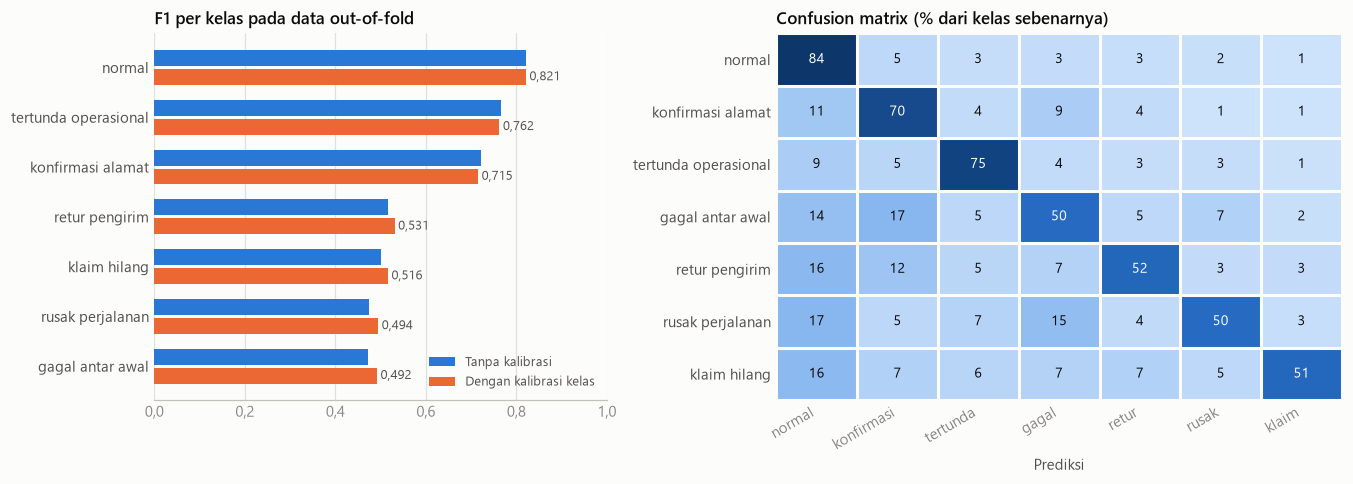

In [23]:
order = np.argsort(per_cf)
fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.5), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]; yy = np.arange(K)
ax.barh(yy + 0.19, per_arg[order], height=0.32, color=BLUE, label="Tanpa kalibrasi")
ax.barh(yy - 0.19, per_cf[order], height=0.32, color=ORANGE, label="Dengan kalibrasi kelas")
for yi, v in zip(yy, per_cf[order]): ax.text(v + 0.008, yi - 0.19, idn(v, 3), va="center", fontsize=8.5, color=INK2)
ax.set_yticks(yy, [CLASSES[i].replace("_", " ") for i in order]); ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: idn(v, 1))); ax.grid(axis="x"); ax.set_axisbelow(True); ax.spines["left"].set_visible(False)
ax.legend(loc="lower right", fontsize=8.5); ax.set_title("F1 per kelas pada data out-of-fold")
cm = np.bincount(y_oof * K + pred_cf.astype(np.int64), minlength=K * K).reshape(K, K).astype(np.float64); cmn = cm / cm.sum(1, keepdims=True)
heatmap(axes[1], cmn, [c.split("_")[0] for c in CLASSES], [c.replace("_", " ") for c in CLASSES], lambda v: f"{v * 100:.0f}")
axes[1].set_title("Confusion matrix (% dari kelas sebenarnya)"); axes[1].set_xlabel("Prediksi")
plt.tight_layout(); plt.show()

**Bacaan.** Pengali kelas menaikkan F1 keempat kelas kecil sebesar 0,015 sampai 0,021, dengan penurunan paling banyak 0,006 pada tiga kelas besar. Kesalahan paling umum pada kelas kecil adalah terbaca `normal` (14 sampai 17%). `gagal_antar_awal` juga sering tertukar dengan `konfirmasi_alamat` (17%), dan `rusak_perjalanan` dengan `gagal_antar_awal` (15%). Bagi tim QC, ini berarti sebagian pengiriman yang diprediksi `normal` tetap perlu diambil sampel untuk diperiksa.

kelompok,porsi_gain_%,jumlah_fitur
str,f64,u32
"""Logit regresi logistik""",86.9,7
"""Fitur pengiriman""",5.6,35
"""Target encoding""",4.6,16
"""Profil entitas""",2.9,12


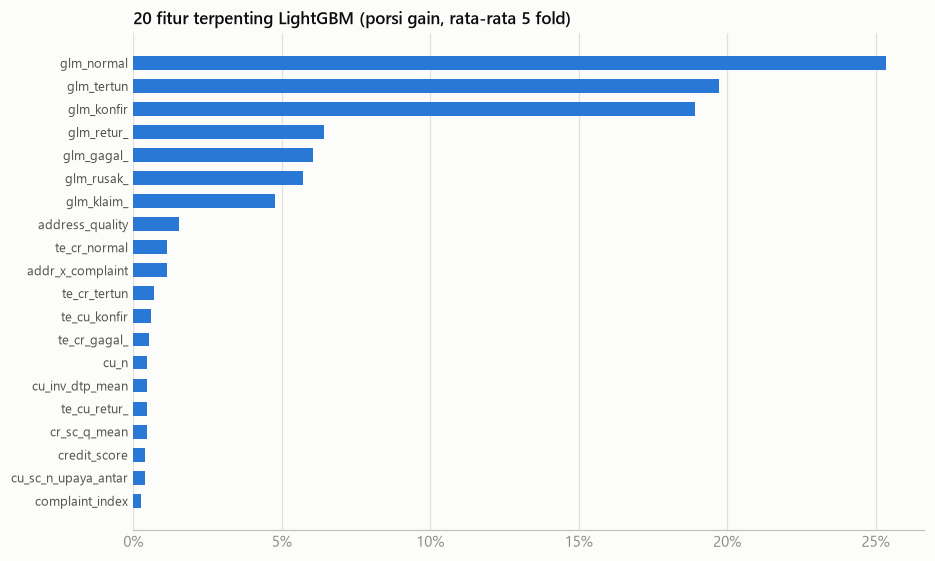

In [24]:
gain = np.zeros(len(STACK_BASE + STACK_TE + GLM_NAMES))
for f in range(N_FOLDS):
    gain += lgb.Booster(model_file=str(MODEL_DIR / f"lgbm_fold{f}.txt")).feature_importance("gain") / N_FOLDS
names = np.array(STACK_BASE + STACK_TE + GLM_NAMES); share = gain / gain.sum()
top = np.argsort(share)[::-1][:20][::-1]
group = lambda n: "Logit regresi logistik" if n.startswith("glm_") else "Target encoding" if n.startswith("te_") else "Profil entitas" if n.startswith(("cu_", "cr_", "hb_", "hm_")) else "Fitur pengiriman"
g = pl.DataFrame({"f": names, "s": share}).with_columns(pl.col("f").map_elements(group, return_dtype=pl.String).alias("kelompok")).group_by("kelompok").agg((pl.col("s").sum() * 100).round(1).alias("porsi_gain_%"), pl.len().alias("jumlah_fitur")).sort("porsi_gain_%", descending=True)
display(g)
fig, ax = plt.subplots(figsize=(8.6, 5.2))
ax.barh(range(20), share[top], height=0.6, color=BLUE)
ax.set_yticks(range(20), names[top], fontsize=8.5); ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v * 100:.0f}%")); ax.grid(axis="x"); ax.set_axisbelow(True); ax.spines["left"].set_visible(False)
ax.set_title("20 fitur terpenting LightGBM (porsi gain, rata-rata 5 fold)")
plt.tight_layout(); plt.show()

**Bacaan.** Logit regresi logistik menyumbang sekitar 87% gain LightGBM, jadi sinyal utamanya bersifat aditif. Logit ini sendiri dihitung dari seluruh fitur numerik dan target encoding, sehingga porsi gain tidak berarti fitur lain tidak berguna. Boosting menambahkan koreksi dari interaksi dan efek entitas. Gain menunjukkan kontribusi di dalam model, bukan hubungan sebab-akibat.

## 8. Inferensi dan pembuatan submission

Tahap ini **tidak melatih apa pun**. Fitur dibangun dari data mentah, lalu semua model dimuat dari folder `models/`. Prediksi dibandingkan dengan salinan referensi yang dihasilkan saat pelatihan untuk memastikan berkas model menghasilkan angka yang sama.

In [25]:
def predict_test(test_df):
    """Inferensi murni: hanya memuat berkas model, tanpa pelatihan apa pun."""
    cfg = json.loads((MODEL_DIR / "feature_config.json").read_text())
    rep = json.loads((MODEL_DIR / "training_report.json").read_text())
    prior = np.array(cfg["prior"]); idx = cfg["idx"]; w = rep["blend_weights"]
    tables = {key: pl.read_parquet(MODEL_DIR / f"te_{key}.parquet") for key, _, _ in TE_ENTITIES}
    T = te_lookup(test_df, tables, prior)
    Xb = test_df.select(pl.col(cfg["base_features"]).cast(pl.Float32)).to_numpy()
    Xg = np.hstack([Xb[:, idx["glm_num"]], T])
    total = np.zeros((len(Xb), K), dtype=np.float64)
    for f in range(cfg["n_folds"]):
        t0 = time.time()
        g = np.load(MODEL_DIR / f"glm_fold{f}.npz")
        st = {k: g[k] for k in ("lo", "med", "hi", "mu", "sd", "keep")}
        Z = glm_transform(Xg, st)
        G = (glm_logits(Z, g["coef_0"], g["intercept_0"]) + glm_logits(Z, g["coef_1"], g["intercept_1"])) / 2
        del Z
        X = np.hstack([Xb[:, idx["stack_base"]], T[:, idx["stack_te"]], G])
        ml = lgb.Booster(model_file=str(MODEL_DIR / f"lgbm_fold{f}.txt"))
        mx = xgb.Booster(); mx.load_model(str(MODEL_DIR / f"xgb_fold{f}.json")); mx.set_param({"nthread": N_THREADS})
        mc = CatBoostClassifier(); mc.load_model(str(MODEL_DIR / f"cat_fold{f}.cbm"))
        total += (w["lgbm"] * np.log(np.clip(ml.predict(X, num_threads=N_THREADS), 1e-9, 1))
                  + w["xgb"] * np.log(np.clip(mx.predict(xgb.DMatrix(X, nthread=N_THREADS)), 1e-9, 1))
                  + w["cat"] * np.log(np.clip(mc.predict_proba(X, thread_count=N_THREADS), 1e-9, 1))) / cfg["n_folds"]
        del ml, mx, mc, X, G; gc.collect()
        print(f"  fold {f}: prediksi selesai ({time.time() - t0:.0f}s)", flush=True)
    return softmax(total).astype(np.float32)

In [26]:
t0 = time.time()
final_cfg = json.loads((MODEL_DIR / "feature_config.json").read_text())
_, test_features, _ = build_features(meta=final_cfg["meta"])
gc.collect()
P_test = predict_test(test_features)
report = json.loads((MODEL_DIR / "training_report.json").read_text())
pred_idx = apply_weights(P_test, np.array(report["class_weights"]))
pred_labels = np.array(CLASSES)[pred_idx]
pred = pl.DataFrame({"shipment_id": test_features["shipment_id"], TARGET: pred_labels})
sample = pl.read_csv(DATA_DIR / "sample_submission.csv")
submission = sample.select("shipment_id").join(pred, on="shipment_id", how="left", maintain_order="left")
submission.write_csv(SUBMISSION_PATH)
print(f"Inferensi selesai dalam {(time.time() - t0) / 60:.1f} menit. Tersimpan di {SUBMISSION_PATH.name}")

ref_path = MODEL_DIR / "reference_test_proba.npy"
if ref_path.exists():
    print(f"Selisih maksimum terhadap prediksi saat pelatihan: {np.abs(P_test - np.load(ref_path)).max():.2e}")

  train: (1243617, 209)  (9s)


  test: (362245, 208)  (14s)


  fitur selesai: train (1243617, 241), test (362245, 240) (16s)


  fold 0: prediksi selesai (35s)


  fold 1: prediksi selesai (34s)


  fold 2: prediksi selesai (47s)


  fold 3: prediksi selesai (39s)


  fold 4: prediksi selesai (37s)


Inferensi selesai dalam 3.5 menit. Tersimpan di submission.csv
Selisih maksimum terhadap prediksi saat pelatihan: 2.98e-07


In [27]:
chk = pl.read_csv(SUBMISSION_PATH)
tests = {
    "Jumlah baris sama dengan sample_submission": chk.height == sample.height,
    "Kolom sesuai format": chk.columns == sample.columns,
    "Urutan shipment_id sama": (chk["shipment_id"] == sample["shipment_id"]).all(),
    "Tidak ada shipment_id ganda": chk["shipment_id"].n_unique() == chk.height,
    "Tidak ada prediksi kosong": chk[TARGET].null_count() == 0,
    "Semua label termasuk tujuh kelas": set(chk[TARGET].unique().to_list()) <= set(CLASSES),
    "Ketujuh kelas muncul": chk[TARGET].n_unique() == K,
}
for k, v in tests.items(): print(("LULUS  " if v else "GAGAL  ") + k)
assert all(tests.values()), "Submission tidak valid"
train_share = np.bincount(y_oof, minlength=K) / len(y_oof)
oof_pred_share = np.bincount(pred_cf, minlength=K) / len(pred_cf)
test_share = chk.group_by(TARGET).len().with_columns((pl.col("len") / pl.col("len").sum()).alias("s"))
test_map = dict(zip(test_share[TARGET], test_share["s"]))
display(pl.DataFrame({"kelas": CLASSES, "porsi_train_%": np.round(train_share * 100, 2), "porsi_prediksi_oof_%": np.round(oof_pred_share * 100, 2), "porsi_prediksi_test_%": np.round([test_map.get(c, 0) * 100 for c in CLASSES], 2)}))
display(chk.head(5))

LULUS  Jumlah baris sama dengan sample_submission
LULUS  Kolom sesuai format
LULUS  Urutan shipment_id sama
LULUS  Tidak ada shipment_id ganda
LULUS  Tidak ada prediksi kosong
LULUS  Semua label termasuk tujuh kelas
LULUS  Ketujuh kelas muncul


kelas,porsi_train_%,porsi_prediksi_oof_%,porsi_prediksi_test_%
str,f64,f64,f64
"""normal""",38.08,39.54,38.82
"""konfirmasi_alamat""",21.94,21.03,20.71
"""tertunda_operasional""",14.92,14.38,14.86
"""gagal_antar_awal""",10.0,10.18,10.52
"""retur_pengirim""",7.06,6.82,7.11
"""rusak_perjalanan""",4.98,5.04,5.01
"""klaim_hilang""",3.03,3.0,2.97


shipment_id,status_penanganan
str,str
"""SHP-5A64RENJ""","""normal"""
"""SHP-BUZSJTV9""","""konfirmasi_alamat"""
"""SHP-EGUZBJHQ""","""normal"""
"""SHP-YWBRSQLZ""","""konfirmasi_alamat"""
"""SHP-JS89CKME""","""tertunda_operasional"""


## 9. Insight bisnis dan keterbatasan

**Rekomendasi untuk tim operasional**

1. **Data alamat adalah tuas terbesar.** `konfirmasi_alamat` adalah kelas masalah terbesar dan sangat terkait dengan kualitas alamat pelanggan. Validasi alamat saat pemesanan berpotensi langsung mengurangi beban ini.
2. **Hub padat perlu kapasitas tambahan di bulan puncak.** Kepadatan tinggi pada bulan Maret serta Oktober sampai Desember berkaitan dengan lonjakan status tertunda.
3. **Klaim hilang terkonsentrasi di barang bernilai tinggi pada hub berotomasi rendah.** Pemeriksaan tambahan untuk kombinasi ini paling efisien untuk tim klaim.
4. **Pembinaan kurir bisa dibuat tepat sasaran.** Rata-rata kualitas scan per kurir mengungkap perbedaan kemampuan yang tidak terlihat dari `courier_score`.
5. **Pelanggan dengan riwayat retur perlu perlakuan khusus,** misalnya konfirmasi sebelum pengiriman COD.

**Cara memakai model.** Keputusan akhir tetap di tangan petugas. Probabilitas model paling cocok dipakai untuk mengurutkan pengiriman yang perlu diperiksa lebih dulu.

**Keterbatasan**

- Kelas `gagal_antar_awal`, `retur_pengirim`, `rusak_perjalanan`, dan `klaim_hilang` masih memiliki F1 sekitar 0,5. Banyak kasus di kelas ini tampak mirip dengan kasus normal pada data yang tersedia.
- Target encoding bekerja paling baik untuk pelanggan yang punya riwayat. Pelanggan baru hanya mengandalkan fitur lain.
- Profil entitas memakai baris train dan test sekaligus. Untuk dipakai di produksi secara harian, profil ini perlu dihitung ulang secara berkala dari data historis.
- Skor OOF adalah estimasi. Skor pada leaderboard bisa berbeda karena sebaran test tidak identik dengan train. Seleksi fitur dan tuning juga memakai holdout dari data train, sehingga skor validasi bisa sedikit optimistis.
- Rekomendasi di atas berasal dari pola pada data historis, belum tentu hubungan sebab-akibat. Dampaknya perlu diuji sebelum dijadikan kebijakan.